# Report 1: Fuzzy C-Means on COVID-19 data (ECDC)

## Step 1: Load the data and integrity checks

Source: ECDC, *COVID-19 Coronavirus data* (EU Open Data Portal), daily file downloaded in two formats
(`data.csv`, `opendata.ecdc.europa.eu.json`). The two files were compared field by field: same 61,900 records,
same values, same missing values; only `day`/`month` are zero-padded strings in the JSON. We use the CSV.

Reference paper: Łuczak & Kalinowski (2022), *Entropy* 24, 14. The paper does not describe any data check, so
every check below is ours. **Nothing is removed in this step**: we only count.

Pitfall: pandas reads the string `"NA"` as missing by default, and `NA` is the `geoId` of Namibia.
So we read with `keep_default_na=False` and only treat empty fields as missing.

In [152]:
from pathlib import Path
import numpy as np
import pandas as pd

# Paths are relative to this notebook (Reports/Report 1/src/covid/)
REPORT_DIR = Path("../..")
DATA_DIR = REPORT_DIR / "data" / "covid"
OUT_DIR = REPORT_DIR / "data" / "covid"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RATE14 = "Cumulative_number_for_14_days_of_COVID-19_cases_per_100000"
df = pd.read_csv(DATA_DIR / "data.csv", keep_default_na=False, na_values=[""])
df["date"] = pd.to_datetime(df["dateRep"], format="%d/%m/%Y")

print("shape:", df.shape)
print(df.dtypes)
print("date range:", df["date"].min().date(), "->", df["date"].max().date(), "|", df["date"].nunique(), "distinct days")
print("countries/territories:", df["countriesAndTerritories"].nunique())
df.head(3)

shape: (61900, 13)
dateRep                                                                  str
day                                                                    int64
month                                                                  int64
year                                                                   int64
cases                                                                  int64
deaths                                                                 int64
countriesAndTerritories                                                  str
geoId                                                                    str
countryterritoryCode                                                     str
popData2019                                                          float64
continentExp                                                             str
Cumulative_number_for_14_days_of_COVID-19_cases_per_100000           float64
date                                                     

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,geoId,countryterritoryCode,popData2019,continentExp,Cumulative_number_for_14_days_of_COVID-19_cases_per_100000,date
0,14/12/2020,14,12,2020,746,6,Afghanistan,AF,AFG,3.80e+07,Asia,9.01,2020-12-14
1,13/12/2020,13,12,2020,298,9,Afghanistan,AF,AFG,3.80e+07,Asia,7.05,2020-12-13
2,12/12/2020,12,12,2020,113,11,Afghanistan,AF,AFG,3.80e+07,Asia,6.87,2020-12-12


### 1a: Missing values

In [153]:
missing = pd.DataFrame({"missing": df.isna().sum(), "missing %": (df.isna().mean() * 100).round(2)})
print(missing[missing["missing"] > 0])
# Which countries have no population / country code?
print(df.loc[df["popData2019"].isna(), "countriesAndTerritories"].value_counts())

                                                    missing  missing %
countryterritoryCode                                    123       0.20
popData2019                                             123       0.20
Cumulative_number_for_14_days_of_COVID-19_cases...     2879       4.65
countriesAndTerritories
Cases_on_an_international_conveyance_Japan    64
Wallis_and_Futuna                             59
Name: count, dtype: int64


### 1b: Keys and consistency

- one row per (country, day)?
- `dateRep` agrees with `day`, `month`, `year`?
- each country has a single `geoId`, `countryterritoryCode`, `popData2019`, `continentExp`?

In [154]:
key = ["countriesAndTerritories", "date"]
print("duplicate (country, day) rows:", df.duplicated(subset=key).sum())
print("fully duplicated rows:", df.duplicated().sum())

rebuilt = pd.to_datetime(dict(year=df["year"], month=df["month"], day=df["day"]))
print("dateRep != day/month/year:", (rebuilt != df["date"]).sum())

attrs = ["geoId", "countryterritoryCode", "popData2019", "continentExp"]
n_values = df.groupby("countriesAndTerritories")[attrs].nunique(dropna=False)
print("countries with more than one value per attribute:")
print((n_values > 1).sum())
print("continents:", df.groupby("continentExp")["countriesAndTerritories"].nunique().to_dict())

duplicate (country, day) rows: 0
fully duplicated rows: 0
dateRep != day/month/year: 0
countries with more than one value per attribute:
geoId                   0
countryterritoryCode    0
popData2019             0
continentExp            0
dtype: int64
continents: {'Africa': 55, 'America': 49, 'Asia': 42, 'Europe': 55, 'Oceania': 12, 'Other': 1}


### 1c: Gaps in the daily series

A country appears from its first reported day. Inside its own range, is every day present?

In [155]:
span = df.groupby("countriesAndTerritories")["date"].agg(first="min", last="max", rows="count")
span["expected"] = (span["last"] - span["first"]).dt.days + 1
span["missing days"] = span["expected"] - span["rows"]
gaps = span[span["missing days"] > 0].sort_values("missing days", ascending=False)
print("countries with gaps:", len(gaps), "| total missing days:", int(span["missing days"].sum()))
print("first reported day: ", span["first"].min().date(), "->", span["first"].max().date())
print("last reported day:  ", span["last"].min().date(), "->", span["last"].max().date())
gaps.head(15)

countries with gaps: 98 | total missing days: 476
first reported day:  2019-12-31 -> 2020-11-11
last reported day:   2020-03-10 -> 2020-12-14


,first,last,rows,expected,missing days
countriesAndTerritories,,,,,
Sint_Maarten,2020-03-03,2020-12-14,264,287,23
Nepal,2019-12-31,2020-12-14,337,350,13
Monaco,2019-12-31,2020-12-14,338,350,12
Nigeria,2019-12-31,2020-12-14,339,350,11
Curaçao,2020-03-13,2020-12-14,266,277,11
Saint_Vincent_and_the_Grenadines,2020-03-13,2020-12-14,266,277,11
Andorra,2020-03-03,2020-12-14,276,287,11
Aruba,2020-03-13,2020-12-14,267,277,10
Ukraine,2020-03-04,2020-12-14,276,286,10


### 1d: Implausible values

- negative daily cases or deaths (ECDC corrections of earlier over-counts);
- deaths > cases on the same day (possible with daily reporting, but it makes the paper's x3 = deaths/cases > 100%);
- cases = 0 with deaths > 0 (x3 undefined);
- cumulative cases or deaths becoming negative (a correction larger than everything reported before).

In [156]:
d = df.sort_values(key).copy()
d["cum_cases"] = d.groupby("countriesAndTerritories")["cases"].cumsum()
d["cum_deaths"] = d.groupby("countriesAndTerritories")["deaths"].cumsum()

checks = {
    "cases < 0": d["cases"] < 0,
    "deaths < 0": d["deaths"] < 0,
    "deaths > cases": d["deaths"] > d["cases"],
    "cases == 0 and deaths > 0": (d["cases"] == 0) & (d["deaths"] > 0),
    "cumulative cases < 0": d["cum_cases"] < 0,
    "cumulative deaths < 0": d["cum_deaths"] < 0,
    "cases > population": d["cases"] > d["popData2019"],
}
implausible = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in checks.items()},
                            "countries": {k: d.loc[v, "countriesAndTerritories"].nunique() for k, v in checks.items()}})
print(implausible)
print("\nnegative values (most negative first):")
neg = d.loc[(d["cases"] < 0) | (d["deaths"] < 0), ["countriesAndTerritories", "dateRep", "cases", "deaths"]]
neg.sort_values(["cases", "deaths"]).head(10)

                           rows  countries
cases < 0                    18         13
deaths < 0                    8          6
deaths > cases              300        115
cases == 0 and deaths > 0   244         98
cumulative cases < 0          0          0
cumulative deaths < 0         0          0
cases > population            0          0

negative values (most negative first):


,countriesAndTerritories,dateRep,cases,deaths
16906,Ecuador,07/09/2020,-8261,3800
17029,Ecuador,07/05/2020,-2461,49
17027,Ecuador,09/05/2020,-1480,50
34442,Luxembourg,28/08/2020,-1385,0
20558,France,03/06/2020,-766,107
52961,Spain,19/04/2020,-713,410
52925,Spain,25/05/2020,-372,-1918
6311,Benin,20/05/2020,-209,0
45901,Portugal,03/05/2020,-161,16
29276,Italy,20/06/2020,-148,47


### 1e: Recompute the 14-day rate

ECDC definition: (sum of daily cases over the last 14 days) / popData2019 × 100,000.
We recompute it from `cases` and compare with the column in the file. This checks that `cases`, the dates and
`popData2019` agree with each other. Two readings of "last 14 days":
- **calendar**: the last 14 calendar days (a day missing from the file counts as 0 cases);
- **rows**: the last 14 rows of that country (a missing day is skipped, so the window can span more than 14 days).

In [157]:
def rate14_calendar(g):
    s = g.set_index("date")["cases"].asfreq("D", fill_value=0)
    return s.rolling(14, min_periods=14).sum().reindex(g["date"]).to_numpy()

def rate14_rows(g):
    return g["cases"].rolling(14, min_periods=14).sum().to_numpy()

by_country = d.groupby("countriesAndTerritories", sort=True)   # d is sorted by country, date
d["rate14_calendar"] = np.concatenate([rate14_calendar(g) for _, g in by_country]) / d["popData2019"] * 1e5
d["rate14_rows"] = np.concatenate([rate14_rows(g) for _, g in by_country]) / d["popData2019"] * 1e5

TOL = 1e-6   # the file stores 8 decimals
rows_14 = []
for col in ["rate14_calendar", "rate14_rows"]:
    both = d[RATE14].notna() & d[col].notna()
    bad = both & ((d[RATE14] - d[col]).abs() > TOL)
    rows_14.append({"definition": col, "compared": int(both.sum()), "mismatch": int(bad.sum()),
                    "countries with mismatch": d.loc[bad, "countriesAndTerritories"].nunique()})
    d[col + "_bad"] = bad
print(pd.DataFrame(rows_14))

bad_rows = d[d["rate14_rows_bad"]]
print("\nmismatches with the 'rows' definition, by country:")
print(bad_rows["countriesAndTerritories"].value_counts())
rel = (bad_rows[RATE14] - bad_rows["rate14_rows"]) / bad_rows["rate14_rows"]
print("relative difference file vs ours (rows):", rel.describe()[["min", "50%", "max"]].round(3).to_dict())
print("file missing although 14 rows exist:", int((d[RATE14].isna() & d["rate14_rows"].notna()).sum()))

        definition  compared  mismatch  countries with mismatch
0  rate14_calendar     59021      1114                       94
1      rate14_rows     59021       585                        2

mismatches with the 'rows' definition, by country:
countriesAndTerritories
Sweden     294
Belgium    291
Name: count, dtype: int64
relative difference file vs ours (rows): {'min': -1.0, '50%': -0.014, 'max': inf}
file missing although 14 rows exist: 0


/home/stefy/Work/University/Master/Anul I/Metode Avansate de Analiza a Datelor/.venv/lib/python3.14/site-packages/pandas/core/nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2


### 1f: Summary table (saved)

In [158]:
summary = pd.DataFrame([
    ("rows", len(df)),
    ("columns", df.shape[1] - 1),
    ("countries/territories", df["countriesAndTerritories"].nunique()),
    ("first day", df["date"].min().date()),
    ("last day", df["date"].max().date()),
    ("duplicate (country, day)", int(df.duplicated(subset=key).sum())),
    ("missing popData2019", int(df["popData2019"].isna().sum())),
    ("missing 14-day rate", int(df[RATE14].isna().sum())),
    ("missing days inside country ranges", int(span["missing days"].sum())),
    *[(k, v) for k, v in implausible["rows"].items()],
    *[(f"14-day rate mismatches ({r['definition']})", r["mismatch"]) for r in rows_14],
], columns=["check", "value"])
summary.to_csv(OUT_DIR / "covid_integrity_checks.csv", index=False)
print("saved:", (OUT_DIR / "covid_integrity_checks.csv").resolve())
summary

saved: /home/stefy/Work/University/Master/Anul I/Metode Avansate de Analiza a Datelor/Reports/Report 1/data/covid/covid_integrity_checks.csv


,check,value
0,rows,61900
1,columns,12
2,countries/territories,214
3,first day,2019-12-31
4,last day,2020-12-14
5,"duplicate (country, day)",0
6,missing popData2019,123
7,missing 14-day rate,2879
8,missing days inside country ranges,476
9,cases < 0,18


## Step 2: The paper's subset (Europe, 4 March – 24 June 2020)

Paper, Section 3: "European countries", daily data from 4 March to 24 June 2020 (T = 113 days).
The exact country list is not given. Table 2 names the countries assigned to a state on three dates
(4 March, 15 April, 24 June); its note says only "countries reporting COVID-19 in a particular period" are listed.
Here we (2a) take ECDC's `continentExp == "Europe"`, (2b) compare it with the countries named in Table 2,
(2c) check which countries had reported cases by 4 March, and (2d) count the problems of Step 1 inside this window.
Nothing is removed yet.

In [159]:
START, END = pd.Timestamp("2020-03-04"), pd.Timestamp("2020-06-24")
T_DAYS = (END - START).days + 1
eu = d[(d["continentExp"] == "Europe") & d["date"].between(START, END)].copy()
print("days in window:", T_DAYS)
print("rows:", len(eu), "| countries:", eu["countriesAndTerritories"].nunique(),
      "| full panel would be:", eu["countriesAndTerritories"].nunique() * T_DAYS)

days in window: 113
rows: 5949 | countries: 55 | full panel would be: 6215


### 2a: Coverage per country in the window

In [160]:
cov = eu.groupby("countriesAndTerritories").agg(first=("date", "min"), last=("date", "max"), rows=("date", "count"),
                                                 pop=("popData2019", "first"))
cov["missing days"] = T_DAYS - cov["rows"]
print("countries with all", T_DAYS, "days:", int((cov["missing days"] == 0).sum()))
cov.sort_values("missing days", ascending=False).head(15)

countries with all 113 days: 17


,first,last,rows,pop,missing days
countriesAndTerritories,,,,,
Isle_of_Man,2020-03-21,2020-06-24,96,8.46e+04,17
Guernsey,2020-03-20,2020-06-24,97,6.45e+04,16
Gibraltar,2020-03-20,2020-06-24,97,3.37e+04,16
Jersey,2020-03-20,2020-06-24,97,1.08e+05,16
Montenegro,2020-03-18,2020-06-24,99,6.22e+05,14
Holy_See,2020-03-07,2020-06-24,102,8.15e+02,11
Andorra,2020-03-14,2020-06-24,102,7.62e+04,11
Monaco,2020-03-15,2020-06-24,102,3.31e+04,11
Ukraine,2020-03-04,2020-06-24,103,4.40e+07,10


### 2b: ECDC "Europe" vs the countries named in the paper (Table 2)

Country names as in Table 2 of the paper, written with ECDC spelling.

In [161]:
PAPER_TABLE2 = ["Albania", "Armenia", "Austria", "Belarus", "Belgium", "Bosnia_and_Herzegovina", "Bulgaria",
                "Croatia", "Cyprus", "Czechia", "Denmark", "Estonia", "Finland", "France", "Georgia", "Germany",
                "Greece", "Hungary", "Iceland", "Ireland", "Italy", "Kosovo", "Latvia", "Liechtenstein", "Lithuania",
                "Luxembourg", "Malta", "Moldova", "Monaco", "Montenegro", "Netherlands", "North_Macedonia", "Norway",
                "Poland", "Portugal", "Romania", "Russia", "San_Marino", "Serbia", "Slovakia", "Slovenia", "Spain",
                "Sweden", "Switzerland", "Ukraine", "United_Kingdom"]
ecdc_eu = set(cov.index)
print("named in Table 2:", len(PAPER_TABLE2))
print("in Table 2 but not ECDC Europe:", sorted(set(PAPER_TABLE2) - ecdc_eu))
print("ECDC Europe but not in Table 2:", sorted(ecdc_eu - set(PAPER_TABLE2)))
cov.loc[sorted(ecdc_eu - set(PAPER_TABLE2)), ["pop", "rows", "missing days"]]

named in Table 2: 46
in Table 2 but not ECDC Europe: []
ECDC Europe but not in Table 2: ['Andorra', 'Azerbaijan', 'Faroe_Islands', 'Gibraltar', 'Guernsey', 'Holy_See', 'Isle_of_Man', 'Jersey', 'Turkey']


,pop,rows,missing days
countriesAndTerritories,,,
Andorra,7.62e+04,102,11
Azerbaijan,1.00e+07,107,6
Faroe_Islands,4.87e+04,111,2
Gibraltar,3.37e+04,97,16
Guernsey,6.45e+04,97,16
Holy_See,8.15e+02,102,11
Isle_of_Man,8.46e+04,96,17
Jersey,1.08e+05,97,16
Turkey,8.20e+07,103,10


### 2c: Who had reported cases by 4 March?

Table 2 lists 25 countries on 4 March (all in "stabilisation"). If the paper only includes a country from its first
reported case, the countries with cumulative cases > 0 on 4 March should be exactly these 25.

In [162]:
PAPER_4MARCH = ["France", "Austria", "Belarus", "Belgium", "Croatia", "Czechia", "Denmark", "Estonia", "Finland",
                "Germany", "Iceland", "Ireland", "Italy", "Netherlands", "Norway", "Poland", "Portugal", "Romania",
                "Russia", "Spain", "Sweden", "Switzerland", "Ukraine", "United_Kingdom", "San_Marino"]
on_4march = d[(d["continentExp"] == "Europe") & (d["date"] == START)]
present = set(on_4march["countriesAndTerritories"])
with_cases = set(on_4march.loc[on_4march["cum_cases"] > 0, "countriesAndTerritories"])
print("rows on 4 March:", len(present), "| with cumulative cases > 0:", len(with_cases))
print("paper lists but no cases yet (ours):", sorted(set(PAPER_4MARCH) - with_cases))
print("cases > 0 (ours) but not listed in paper:", sorted(with_cases - set(PAPER_4MARCH)))

rows on 4 March: 25 | with cumulative cases > 0: 25
paper lists but no cases yet (ours): []
cases > 0 (ours) but not listed in paper: []


### 2d: Problems from Step 1 inside the window

In [163]:
eu_checks = {
    "cases < 0": eu["cases"] < 0,
    "deaths < 0": eu["deaths"] < 0,
    "deaths > cases": eu["deaths"] > eu["cases"],
    "cases == 0 and deaths > 0": (eu["cases"] == 0) & (eu["deaths"] > 0),
    "missing 14-day rate": eu[RATE14].isna(),
    "missing population": eu["popData2019"].isna(),
}
eu_problems = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in eu_checks.items()},
                            "countries": {k: eu.loc[v, "countriesAndTerritories"].nunique() for k, v in eu_checks.items()}})
eu_problems.loc["missing days (absent rows)"] = [int(cov["missing days"].sum()), int((cov["missing days"] > 0).sum())]
print(eu_problems)
print("\nnegative values:")
print(eu.loc[(eu["cases"] < 0) | (eu["deaths"] < 0), ["countriesAndTerritories", "dateRep", "cases", "deaths"]])
print("\nmissing 14-day rate, by country:")
print(eu.loc[eu[RATE14].isna(), "countriesAndTerritories"].value_counts().head(10))
eu_problems.to_csv(OUT_DIR / "covid_europe_window_problems.csv")
cov.to_csv(OUT_DIR / "covid_europe_window_coverage.csv")
print("saved: covid_europe_window_problems.csv, covid_europe_window_coverage.csv")

                            rows  countries
cases < 0                      7          6
deaths < 0                     1          1
deaths > cases                66         25
cases == 0 and deaths > 0     47         16
missing 14-day rate          322         25
missing population             0          0
missing days (absent rows)   266         38

negative values:
      countriesAndTerritories     dateRep  cases  deaths
20558                  France  03/06/2020   -766     107
29276                   Italy  20/06/2020   -148      47
34222               Lithuania  29/04/2020   -105       3
45901                Portugal  03/05/2020   -161      16
48566              San_Marino  11/05/2020     -9       0
52961                   Spain  19/04/2020   -713     410
52925                   Spain  25/05/2020   -372   -1918

missing 14-day rate, by country:
countriesAndTerritories
Albania                   13
Bosnia_and_Herzegovina    13
Bulgaria                  13
Cyprus                    13


## Step 3: Which preprocessing reproduces the paper's Table 1?

The paper does not describe any data preparation (Step 2: it only names the source). Its Table 1 has
min = 0.00 for all four variables, although the raw data in its window contain negative daily cases
(France, Spain, Italy, Portugal, Lithuania, San Marino, all in the paper's country list). So the authors treated
negatives somehow. ECDC: a negative daily value is a downward revision of the cumulative total
(duplicates / misclassified cases removed), not an event on that day.

Variables (paper, Section 3), per country-day:
- x1 = cases / popData2019 × 100,000
- x2 = deaths / popData2019 × 100,000
- x3 = deaths / cases × 100 (%)
- x4 = ECDC's 14-day cumulative cases per 100,000 (the column in the file)

Objects: country-days, 4 March – 24 June 2020, rows as present in the file (Step 2c).
A first run with only the 46 countries named in Table 2 missed the maxima of x1 (104.5 vs 490.8) and x4
(571.8 vs 858.9). Both paper maxima are exactly the **Holy See** (pop. 815): 4 cases on 27 March 2020 =
490.80 per 100,000, and a 14-day rate of 858.90. So the paper used more countries than Table 2 names.
Variants:
- countries: **46** (Table 2), **47** (Table 2 + Holy See), **55** (all ECDC "Europe");
- negatives: **A** set to 0, **B** drop the row;
- x3 when cases = 0: **i** set to 0, **ii** leave missing;
- x4 missing (first 13 days of a country, Step 1e): **m** leave missing, **z** set to 0.

Statistics as in Table 1. Missing values are skipped variable by variable. CV = SD / mean × 100,
QCOD = (Q3 − Q1) / (Q3 + Q1) × 100. The paper does not say whether SD uses n or n − 1; with ~5,000 rows the
difference is negligible.

In [164]:
PAPER_T1 = pd.DataFrame(
    {"min": [0.00, 0.00, 0.00, 0.00], "mean": [3.04, 0.16, 6.07, 39.80], "max": [490.80, 17.42, 400.00, 858.90],
     "SD": [10.00, 0.53, 16.27, 74.90], "CV": [329.17, 339.94, 268.05, 188.20], "Q1": [0.16, 0.00, 0.00, 3.77],
     "Q2": [0.82, 0.01, 0.72, 12.74], "Q3": [2.65, 0.09, 6.39, 40.78], "IQR": [2.48, 0.09, 6.39, 37.02],
     "QCOD": [88.41, 100.00, 100.00, 83.09]},
    index=["x1", "x2", "x3", "x4"])

in_window = d[(d["continentExp"] == "Europe") & d["date"].between(START, END)]
COUNTRY_SETS = {"46": PAPER_TABLE2, "47": PAPER_TABLE2 + ["Holy_See"],
                "55": sorted(in_window["countriesAndTerritories"].unique())}
for k, cs in COUNTRY_SETS.items():
    print(f"set {k}: {len(cs)} countries, {int(in_window['countriesAndTerritories'].isin(cs).sum())} rows")

def build(countries, neg, x3_zero, x4_zero):
    b = in_window[in_window["countriesAndTerritories"].isin(countries)].copy()
    if neg == "A":
        b["cases"] = b["cases"].clip(lower=0)
        b["deaths"] = b["deaths"].clip(lower=0)
    else:
        b = b[(b["cases"] >= 0) & (b["deaths"] >= 0)]
    X = pd.DataFrame(index=b.index)
    X["x1"] = b["cases"] / b["popData2019"] * 1e5
    X["x2"] = b["deaths"] / b["popData2019"] * 1e5
    X["x3"] = (b["deaths"] / b["cases"].where(b["cases"] > 0) * 100)
    if x3_zero:
        X["x3"] = X["x3"].fillna(0.0)
    X["x4"] = b[RATE14].fillna(0.0) if x4_zero else b[RATE14]
    return X

def table1(X):
    q = X.quantile([0.25, 0.5, 0.75])
    t = pd.DataFrame({"min": X.min(), "mean": X.mean(), "max": X.max(), "SD": X.std(),
                      "Q1": q.loc[0.25], "Q2": q.loc[0.5], "Q3": q.loc[0.75]})
    t["CV"] = t["SD"] / t["mean"] * 100
    t["IQR"] = t["Q3"] - t["Q1"]
    t["QCOD"] = t["IQR"] / (t["Q3"] + t["Q1"]) * 100
    t["n"] = X.notna().sum()
    return t[["n"] + list(PAPER_T1.columns)]

variants = {f"{cs}-{neg}-{'i' if z else 'ii'}-{'z' if z4 else 'm'}": build(COUNTRY_SETS[cs], neg, z, z4)
            for cs in COUNTRY_SETS for neg in ["A", "B"] for z in [True, False] for z4 in [False, True]}
tables = {k: table1(X) for k, X in variants.items()}
pd.set_option("display.precision", 2)
print("Paper, Table 1:"); print(PAPER_T1)
for k in ["46-A-i-m", "47-A-i-m", "55-A-i-m", "55-A-i-z"]:
    print(f"\nVariant {k}:"); print(tables[k].round(2))

set 46: 46 countries, 5037 rows
set 47: 47 countries, 5139 rows
set 55: 55 countries, 5949 rows
Paper, Table 1:
    min   mean     max     SD      CV    Q1     Q2     Q3    IQR    QCOD
x1  0.0   3.04  490.80  10.00  329.17  0.16   0.82   2.65   2.48   88.41
x2  0.0   0.16   17.42   0.53  339.94  0.00   0.01   0.09   0.09  100.00
x3  0.0   6.07  400.00  16.27  268.05  0.00   0.72   6.39   6.39  100.00
x4  0.0  39.80  858.90  74.90  188.20  3.77  12.74  40.78  37.02   83.09

Variant 46-A-i-m:
       n  min   mean     max     SD      CV    Q1     Q2     Q3    IQR    QCOD
x1  5037  0.0   2.59  104.49   5.49  212.46  0.24   0.88   2.64   2.40   83.42
x2  5037  0.0   0.15   17.42   0.51  336.58  0.00   0.02   0.10   0.10  100.00
x3  5037  0.0   6.46  400.00  15.71  243.22  0.00   1.63   7.41   7.41  100.00
x4  4818  0.0  35.98  571.79  60.71  168.72  5.03  13.66  40.06  35.03   77.68

Variant 47-A-i-m:
       n  min   mean     max     SD      CV    Q1     Q2     Q3    IQR    QCOD
x1  5139  0

### 3b: Distance to the paper

For each variant and statistic: relative difference |ours − paper| / |paper| (skipped where the paper's value is 0).
The variant with the smallest differences is the most likely reconstruction. Note: the paper rounds to
2 decimals, so for very small values (x2: Q2 = 0.01) a large *relative* difference can be pure rounding.

In [165]:
stats = ["mean", "max", "SD", "CV", "Q1", "Q2", "Q3", "IQR", "QCOD"]
rel = {}
for k, t in tables.items():
    r = (t[stats] - PAPER_T1[stats]).abs() / PAPER_T1[stats].abs().replace(0, np.nan)
    rel[k] = r
summary3 = pd.DataFrame({k: {"median rel. diff": float(np.nanmedian(r.values)), "max rel. diff": float(np.nanmax(r.values))}
                         for k, r in rel.items()}).T
print(summary3.sort_values("median rel. diff").round(4).head(8))
best = summary3["median rel. diff"].idxmin()
print(f"\nrelative difference (%), best variant {best}:"); print((rel[best] * 100).round(1))
pd.concat(tables, names=["variant", "variable"]).to_csv(OUT_DIR / "covid_table1_variants.csv")
print("saved: covid_table1_variants.csv")

           median rel. diff  max rel. diff
55-A-i-z           7.10e-03           0.43
55-B-i-z           7.70e-03           0.43
55-B-ii-z          8.00e-03           1.91
55-A-ii-z          8.00e-03           1.91
55-B-i-m           1.21e-02           0.43
55-A-i-m           1.28e-02           0.43
55-B-ii-m          2.86e-02           1.91
55-A-ii-m          2.98e-02           1.91

relative difference (%), best variant 55-A-i-z:
    mean  max   SD   CV   Q1    Q2   Q3  IQR  QCOD
x1   0.6  0.0  0.9  0.3  4.3   2.1  0.7  0.9   0.2
x2   3.8  0.0  1.1  0.2  NaN  42.9  3.0  3.0   0.0
x3   1.3  0.0  1.1  0.2  NaN  16.7  2.2  2.2   0.0
x4   0.3  0.0  0.7  0.4  2.1   2.2  0.3  0.1   0.4
saved: covid_table1_variants.csv


## Step 4: Reference data matrix (reproduces the paper)

Decision (19 Nov 2026): the variant that best reproduces Table 1 (Step 3) is our **reference** variant:
all 55 ECDC "Europe" countries, 4 March – 24 June 2020, rows as present in the file; negative daily cases/deaths
set to 0; x3 = 0 when cases = 0; missing 14-day rate set to 0.

Paper, Section 2, eq. (1): the matrix of T·N × K country-days is standardised with the classical z-score
(mean and SD of each variable over **all** country-days pooled), then FCM with Euclidean distance.
We save both the raw x1–x4 and the z-scored matrix. A "clean" variant of our own comes in the next step.

In [166]:
X_ref = build(COUNTRY_SETS["55"], "A", True, True)
ref = in_window.loc[X_ref.index, ["countriesAndTerritories", "geoId", "date", "popData2019"]].join(X_ref)
ref = ref.sort_values(["countriesAndTerritories", "date"]).reset_index(drop=True)
FEATS = ["x1", "x2", "x3", "x4"]

print("shape:", ref.shape, "| missing:", int(ref[FEATS].isna().sum().sum()))
print(table1(ref[FEATS]).round(2))

ref_z = ref.copy()
ref_z[FEATS] = (ref[FEATS] - ref[FEATS].mean()) / ref[FEATS].std(ddof=0)   # population SD; ddof=1 changes nothing visible
print("\nz-score check (mean ~ 0, SD ~ 1):")
print(ref_z[FEATS].agg(["mean", "std"]).round(3))

shape: (5949, 8) | missing: 0
       n  min   mean     max     SD      CV    Q1     Q2     Q3    IQR    QCOD
x1  5949  0.0   3.02  490.80   9.91  328.13  0.17   0.84   2.67   2.50   88.23
x2  5949  0.0   0.15   17.42   0.52  340.55  0.00   0.01   0.09   0.09  100.00
x3  5949  0.0   5.99  400.00  16.09  268.57  0.00   0.84   6.25   6.25  100.00
x4  5949  0.0  39.66  858.90  74.35  187.45  3.85  13.03  40.90  37.05   82.79

z-score check (mean ~ 0, SD ~ 1):
       x1   x2   x3   x4
mean  0.0  0.0  0.0  0.0
std   1.0  1.0  1.0  1.0


### 4a: Shape of the distributions

Same checks as for the other Report 1 datasets: skewness, share of exact zeros, extreme values
(|z| > 3), and correlations. These matter for FCM: with z-score + Euclidean distance, a few extreme
country-days (e.g. the Holy See) can pull a prototype on their own.

In [167]:
shape = pd.DataFrame({
    "skewness": ref[FEATS].skew(),
    "zeros %": (ref[FEATS] == 0).mean() * 100,
    "|z| > 3 rows": (ref_z[FEATS].abs() > 3).sum(),
    "max z": ref_z[FEATS].max(),
})
print(shape.round(2))
print("\nrows with any |z| > 3:", int((ref_z[FEATS].abs() > 3).any(axis=1).sum()))
print("\ncountries behind the |z| > 3 rows:")
print(ref_z.loc[(ref_z[FEATS].abs() > 3).any(axis=1), "countriesAndTerritories"].value_counts().head(10))
print("\nPearson correlation:"); print(ref[FEATS].corr().round(2))
print("\nSpearman correlation:"); print(ref[FEATS].corr(method="spearman").round(2))

    skewness  zeros %  |z| > 3 rows  max z
x1     24.00    15.11            61  49.21
x2     12.29    46.01            86  32.92
x3     10.45    46.88            68  24.50
x4      4.14     9.53           140  11.02

rows with any |z| > 3: 272

countries behind the |z| > 3 rows:
countriesAndTerritories
San_Marino       62
Andorra          37
Holy_See         30
Belgium          24
Luxembourg       16
Faroe_Islands    10
Jersey           10
Isle_of_Man       9
France            8
Spain             8
Name: count, dtype: int64

Pearson correlation:
      x1    x2    x3    x4
x1  1.00  0.17 -0.02  0.45
x2  0.17  1.00  0.33  0.39
x3 -0.02  0.33  1.00  0.04
x4  0.45  0.39  0.04  1.00

Spearman correlation:
      x1    x2    x3    x4
x1  1.00  0.57  0.40  0.71
x2  0.57  1.00  0.90  0.57
x3  0.40  0.90  1.00  0.39
x4  0.71  0.57  0.39  1.00


In [168]:
ref.to_csv(OUT_DIR / "covid_ref_raw.csv", index=False)
ref_z.to_csv(OUT_DIR / "covid_ref_zscore.csv", index=False)
shape.to_csv(OUT_DIR / "covid_ref_shape.csv")
print("saved: covid_ref_raw.csv, covid_ref_zscore.csv, covid_ref_shape.csv")

saved: covid_ref_raw.csv, covid_ref_zscore.csv, covid_ref_shape.csv


## Step 5: Our "clean" variant (and a control variant)

Decided with Stefan (19 Nov 2026). The reference variant (Step 4) reproduces the paper, but has four problems
that we can criticise: extreme values from microstates, x4 = 0 at the start of each series, noisy daily
values (ECDC: daily counts are "frequently subject to retrospective corrections, delays in reporting and/or
clustered reporting"), and very skewed distributions. The clean variant changes all four:

1. **Countries:** drop entities with fewer than 100,000 inhabitants (popData2019).
   Control variant: drop only the Holy See (815 inhabitants), everything else as in the clean variant.
2. **x4 missing** (first 13 reported days of a country): drop those rows instead of setting x4 = 0.
3. **7-day averages** for x1–x3: x1 and x2 use the mean of the last 7 reported days (negatives set to 0 first,
   as in the reference); x3 = deaths over the last 7 days / cases over the last 7 days × 100. The window uses the
   last 7 *rows*, like ECDC's own 14-day rate (Step 1e), and is computed on the whole series, so 4 March already
   has its 6 previous days. x3 = 0 when there are no deaths in the window; rows with deaths but no cases in the
   window are dropped (counted below).
4. **log1p** of x1–x4, then the pooled z-score (as for WDBC).

In [169]:
POP_MIN = 100_000
eu_all = d[d["continentExp"] == "Europe"].sort_values(["countriesAndTerritories", "date"]).copy()
eu_all["cases0"] = eu_all["cases"].clip(lower=0)
eu_all["deaths0"] = eu_all["deaths"].clip(lower=0)
g = eu_all.groupby("countriesAndTerritories")
eu_all["cases7"] = g["cases0"].transform(lambda s: s.rolling(7, min_periods=7).sum())
eu_all["deaths7"] = g["deaths0"].transform(lambda s: s.rolling(7, min_periods=7).sum())

small = sorted(eu_all.loc[eu_all["popData2019"] < POP_MIN, "countriesAndTerritories"].unique())
print(f"entities with < {POP_MIN:,} inhabitants ({len(small)}):", small)

def build_clean(exclude):
    b = eu_all[eu_all["date"].between(START, END) & ~eu_all["countriesAndTerritories"].isin(exclude)].copy()
    log = {"rows in window": len(b)}
    b = b[b[RATE14].notna()];                                   log["after dropping missing x4"] = len(b)
    b = b[b["cases7"].notna()];                                 log["after requiring 7 days of history"] = len(b)
    undefined = (b["cases7"] == 0) & (b["deaths7"] > 0)
    b = b[~undefined];                                          log["after dropping deaths7 > 0 with cases7 = 0"] = len(b)
    X = pd.DataFrame({
        "countriesAndTerritories": b["countriesAndTerritories"], "date": b["date"], "popData2019": b["popData2019"],
        "x1": b["cases7"] / 7 / b["popData2019"] * 1e5,
        "x2": b["deaths7"] / 7 / b["popData2019"] * 1e5,
        "x3": np.where(b["deaths7"] == 0, 0.0, b["deaths7"] / b["cases7"].where(b["cases7"] > 0) * 100),
        "x4": b[RATE14],
    }).reset_index(drop=True)
    log["countries"] = X["countriesAndTerritories"].nunique()
    return X, log

clean, log_clean = build_clean(small)
control, log_control = build_clean(["Holy_See"])
print(pd.DataFrame({"clean": log_clean, "control (no Holy See)": log_control}))

entities with < 100,000 inhabitants (9): ['Andorra', 'Faroe_Islands', 'Gibraltar', 'Guernsey', 'Holy_See', 'Isle_of_Man', 'Liechtenstein', 'Monaco', 'San_Marino']
                                            clean  control (no Holy See)
rows in window                               5023                   5847
after dropping missing x4                    4791                   5538
after requiring 7 days of history            4791                   5538
after dropping deaths7 > 0 with cases7 = 0   4786                   5533
countries                                      46                     54


### 5a: Descriptive statistics (same layout as Table 1)

In [170]:
for name, X in [("reference", ref), ("clean", clean), ("control", control)]:
    print(f"\n{name}:"); print(table1(X[FEATS]).round(2))


reference:
       n  min   mean     max     SD      CV    Q1     Q2     Q3    IQR    QCOD
x1  5949  0.0   3.02  490.80   9.91  328.13  0.17   0.84   2.67   2.50   88.23
x2  5949  0.0   0.15   17.42   0.52  340.55  0.00   0.01   0.09   0.09  100.00
x3  5949  0.0   5.99  400.00  16.09  268.57  0.00   0.84   6.25   6.25  100.00
x4  5949  0.0  39.66  858.90  74.35  187.45  3.85  13.03  40.90  37.05   82.79

clean:
       n  min   mean     max     SD      CV    Q1     Q2     Q3    IQR   QCOD
x1  4786  0.0   2.27   27.02   3.30  145.18  0.39   1.00   2.67   2.28  74.50
x2  4786  0.0   0.14    2.49   0.29  205.52  0.01   0.04   0.12   0.11  87.53
x3  4786  0.0   7.00  300.00  12.81  183.00  1.03   3.50   8.40   7.37  78.18
x4  4786  0.0  30.95  348.92  44.22  142.88  5.33  13.63  37.00  31.67  74.83

control:
       n  min   mean     max     SD      CV    Q1     Q2     Q3    IQR   QCOD
x1  5533  0.0   2.83   44.45   5.01  176.98  0.36   1.00   3.02   2.67  78.86
x2  5533  0.0   0.16    6.22 

### 5b: Shape after log1p + z-score, compared with the reference (z-score only)

In [171]:
def log1p_z(X):
    Z = X.copy()
    L = np.log1p(X[FEATS])
    Z[FEATS] = (L - L.mean()) / L.std(ddof=0)
    return Z

clean_z, control_z = log1p_z(clean), log1p_z(control)
rows = []
for name, X, Z in [("reference (z)", ref, ref_z), ("clean (log1p+z)", clean, clean_z), ("control (log1p+z)", control, control_z)]:
    for f in FEATS:
        rows.append({"variant": name, "variable": f, "skew before": X[f].skew(), "skew after": Z[f].skew(),
                     "zeros %": (X[f] == 0).mean() * 100, "|z|>3 rows": int((Z[f].abs() > 3).sum()), "max z": Z[f].max()})
shape5 = pd.DataFrame(rows).set_index(["variant", "variable"])
print(shape5.round(2))
for name, Z in [("clean", clean_z), ("control", control_z)]:
    out = (Z[FEATS].abs() > 3).any(axis=1)
    print(f"\n{name}: rows with any |z| > 3: {int(out.sum())}")
    print(Z.loc[out, "countriesAndTerritories"].value_counts().head(8))
print("\nclean, Pearson on log1p:"); print(np.log1p(clean[FEATS]).corr().round(2))
print("\nclean, Spearman:"); print(clean[FEATS].corr(method="spearman").round(2))

                            skew before  skew after  zeros %  |z|>3 rows  \
variant           variable                                                 
reference (z)     x1              24.00       24.00    15.11          61   
                  x2              12.29       12.29    46.01          86   
                  x3              10.45       10.45    46.88          68   
                  x4               4.14        4.14     9.53         140   
clean (log1p+z)   x1               2.93        0.95     0.61          21   
                  x2               3.85        2.87    15.32         141   
                  x3               8.45        0.27    15.32          26   
                  x4               2.81       -0.00     0.54           0   
control (log1p+z) x1               3.83        1.07     5.01          52   
                  x2               5.37        3.11    22.77         165   
                  x3              13.23        0.38    22.77          14   
            

In [172]:
clean.to_csv(OUT_DIR / "covid_clean_raw.csv", index=False)
clean_z.to_csv(OUT_DIR / "covid_clean_log1p_zscore.csv", index=False)
control.to_csv(OUT_DIR / "covid_control_raw.csv", index=False)
control_z.to_csv(OUT_DIR / "covid_control_log1p_zscore.csv", index=False)
shape5.to_csv(OUT_DIR / "covid_variants_shape.csv")
print("saved: covid_clean_*.csv, covid_control_*.csv, covid_variants_shape.csv")

saved: covid_clean_*.csv, covid_control_*.csv, covid_variants_shape.csv


## Step 6: Choosing the number of classes c

Paper (Section 2, stage 5, and Section 3): k-means for G = 2..10 (R `clusterSim`, classical z-score), assessed with
the Krzanowski–Lai index, eq. (3):

    DIFF(G) = (G − 1)^(2/K) · trW(G − 1) − G^(2/K) · trW(G),   KL(G) = |DIFF(G) / DIFF(G + 1)|

where trW(G) is the within-cluster sum of squares of the best G-partition and K = 4 variables.
"When KL(G) reaches the first local maximum ... the best partition is into G* clusters." The paper got G* = 3.
trW(1) is the total sum of squares; KL(10) needs trW(11).

In addition (as for the other Report 1 datasets): FCM with m = 2 (the paper does not report m; 2 is the default
of `fclust::FKM`, which they used), c = 2..10, 10 random starts, and the validity indices of `fcm.py`
(PC, NPC, PE, NPE, XB, FS). Partitions with coinciding prototypes (n_distinct < c) are flagged as degenerate.

Three data matrices: **reference** (z-score, reproduces the paper), **clean** (log1p + z), **control** (log1p + z,
only the Holy See removed).

In [173]:
import sys, time
sys.path.insert(0, "..")          # make src/ importable (this notebook is in src/covid/)
import importlib
import fcm
importlib.reload(fcm)
from sklearn.cluster import KMeans

SEED = 42
FCM_EPS, FCM_MAX_ITER = 1e-5, 1000
C_RANGE = range(2, 11)
N_INIT = 10
M_MAIN = 2.0
INDICES = {"PC": "max", "NPC": "max", "PE": "min", "NPE": "min", "XB": "min", "FS": "min"}

data = {"reference": ref_z[FEATS].to_numpy(dtype=float),
        "clean": clean_z[FEATS].to_numpy(dtype=float),
        "control": control_z[FEATS].to_numpy(dtype=float)}
for k, A in data.items():
    print(f"{k:10s} {A.shape}")

reference  (5949, 4)
clean      (4786, 4)
control    (5533, 4)


### 6a: k-means + Krzanowski–Lai (the paper's procedure)

In [174]:
def krzanowski_lai(W, K):
    """W: dict G -> trW(G) for G = 1..Gmax+1. Returns dict G -> KL(G) for G = 2..Gmax."""
    diff = {G: (G - 1) ** (2 / K) * W[G - 1] - G ** (2 / K) * W[G] for G in range(2, max(W) + 1)}
    return {G: abs(diff[G] / diff[G + 1]) for G in range(2, max(W))}

def first_local_max(kl):
    Gs = sorted(kl)
    for i, G in enumerate(Gs):
        left = kl[Gs[i - 1]] if i > 0 else -np.inf
        right = kl[Gs[i + 1]] if i + 1 < len(Gs) else -np.inf
        if kl[G] > left and kl[G] > right:
            return G
    return None

kl_rows = []
for name, A in data.items():
    W = {1: float(((A - A.mean(axis=0)) ** 2).sum())}
    for G in range(2, 12):
        W[G] = float(KMeans(n_clusters=G, n_init=N_INIT, random_state=SEED).fit(A).inertia_)
    kl = krzanowski_lai(W, A.shape[1])
    for G in sorted(kl):
        kl_rows.append({"variant": name, "G": G, "trW": W[G], "KL": kl[G]})
    print(f"{name:10s} first local max of KL: G = {first_local_max(kl)} | global max: G = {max(kl, key=kl.get)}")
kl_table = pd.DataFrame(kl_rows)
kl_table.to_csv(OUT_DIR / "covid_kmeans_kl.csv", index=False)
kl_table.pivot(index="G", columns="variant", values="KL").round(3)

reference  first local max of KL: G = 2 | global max: G = 2
clean      first local max of KL: G = 2 | global max: G = 2
control    first local max of KL: G = 2 | global max: G = 4


variant,clean,control,reference
G,,,
2,2.83,2.58,4.03
3,0.44,0.42,0.47
4,2.71,3.86,0.44
5,1.38,0.86,0.71
6,1.31,1.71,1.31
7,1.26,0.89,1.06
8,1.01,1.47,0.80
9,1.32,1.13,2.33
10,1.39,1.13,0.62


### 6b: FCM validity indices, m = 2, c = 2..10

In [175]:
grid_rows, grid_runs = [], {}
t0 = time.time()
for name, A in data.items():
    for c in C_RANGE:
        best, info = fcm.fcm_multistart(A, c, m=M_MAIN, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        grid_runs[(name, c)] = best
        grid_rows.append({"variant": name, "c": c, **fcm.validity_indices(A, best, M_MAIN),
                          **fcm.prototype_diagnostics(A, best), "J": best.J, "iterations": best.n_iter,
                          "n_at_best": info["n_at_best"], "n_not_converged": info["n_not_converged"]})
    g = pd.DataFrame(grid_rows).query("variant == @name")
    print(f"{name:10s} distinct prototypes per c: {g['n_distinct'].tolist()}  starts at best J: {g['n_at_best'].tolist()}  "
          f"not converged: {g['n_not_converged'].tolist()}  ({time.time() - t0:.0f} s)")
grid = pd.DataFrame(grid_rows)
grid.to_csv(OUT_DIR / "covid_fcm_c_grid.csv", index=False)

def preferred_c(g):
    out = []
    for name, gg in g.groupby("variant", sort=False):
        valid = gg[gg["n_distinct"] == gg["c"]].set_index("c")
        out.append({"variant": name, **{idx: (valid[idx].idxmax() if d == "max" else valid[idx].idxmin())
                                        for idx, d in INDICES.items()}})
    return pd.DataFrame(out).set_index("variant")

pref = preferred_c(grid)
pref["KL (k-means, first local max)"] = [first_local_max(dict(zip(g["G"], g["KL"])))
                                        for _, g in kl_table.groupby("variant", sort=False)]
pref.to_csv(OUT_DIR / "covid_c_preferred.csv")
print(pref)
grid.set_index(["variant", "c"])[["PC", "NPC", "PE", "NPE", "XB", "n_distinct", "mean_max_u"]].round(3)

reference  distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  starts at best J: [10, 10, 7, 10, 6, 10, 7, 5, 1]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (14 s)
clean      distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  starts at best J: [10, 10, 10, 10, 10, 10, 10, 10, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (26 s)
control    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  starts at best J: [10, 10, 10, 10, 10, 10, 10, 10, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (35 s)
           PC  NPC  PE  NPE  XB  FS  KL (k-means, first local max)
variant                                                           
reference   2    2   2    2   2  10                              2
clean       2    4   2   10   9  10                              2
control     2    4   2   10   4  10                              2


PC   NPC    PE   NPE    XB  n_distinct  mean_max_u
variant   c                                                       
reference 2   0.86  0.73  0.23  0.32  0.28           2        0.90
          3   0.78  0.68  0.39  0.35  0.51           3        0.84
          4   0.71  0.62  0.53  0.39  0.99           4        0.79
          5   0.72  0.65  0.57  0.36  0.47           5        0.80
          6   0.70  0.64  0.64  0.36  0.45           6        0.79
          7   0.66  0.60  0.72  0.37  1.08           7        0.76
          8   0.63  0.58  0.80  0.38  1.15           8        0.73
          9   0.61  0.57  0.83  0.38  1.69           9        0.72
          10  0.60  0.56  0.89  0.39  1.89          10        0.70
clean     2   0.72  0.45  0.43  0.63  0.26           2        0.81
          3   0.61  0.42  0.68  0.62  0.36           3        0.72
          4   0.59  0.45  0.79  0.57  0.20           4        0.71
          5   0.54  0.42  0.92  0.57  0.30           5        0.67
          6   0.50  0.40  1.04  0.58  0.26           6        0.64
          7   0.48  0.39  1.13  0.58  0.28           7        0.62
          8   0.47  0.39  1.18  0.57  0.25           8        0.61
          9   0.45  0.39  1.25  0.57  0.19           9        0.60
          10  0.44  0.38  1.30  0.57  0.24          10        0.59
control   2   0.72  0.44  0.44  0.63  0.27           2        0.81
          3   0.62  0.43  0.67  0.60  0.34           3        0.73
          4   0.59  0.46  0.77  0.56  0.19           4        0.72
          5   0.54  0.42  0.92  0.57  0.35           5        0.67
          6   0.50  0.40  1.04  0.58  0.23           6        0.64
          7   0.49  0.41  1.10  0.56  0.24           7        0.63
          8   0.48  0.41  1.15  0.55  0.23           8        0.62
          9   0.47  0.40  1.21  0.55  0.23           9        0.61
          10  0.46  0.40  1.27  0.55  0.20          10        0.60

## Step 7: FCM with c = 3, interpreted as in the paper

Paper, Section 3: FCM (`fclust::FKM`) with G = 3 on the z-scored country-days; the states are named from the class
means (Table 3): **stabilisation** (all four variables below the European mean), **destabilisation** (above),
**expansion** (far above, e.g. x4 = 183.6). A state is **partial** when the largest membership is < 0.5.
Table 2 lists the states of the countries on 4 March, 15 April and 24 June 2020. Figure 2 shows the memberships over
time for 8 countries, Figure 5 the normalised entropy per country, eq. (8), Figure 6 the daily entropy, eq. (10),
both with logarithm base G (so 0 = crisp, 1 = all memberships equal).

We take the best of the 10 FCM starts at c = 3 from Step 6, for the **reference** and the **clean** variant.
Clusters are ordered by their mean x4 (lowest = stabilisation), so the labels are comparable across variants.
Class means are computed on the original (unscaled) variables, both weighted by the memberships u and for the
hard assignment (largest membership); the paper does not say which it used.

In [176]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG_DIR = REPORT_DIR / "figures" / "covid"
FIG_DIR.mkdir(parents=True, exist_ok=True)

C_PAPER = 3
STATE_NAMES = ["stabilisation", "destabilisation", "expansion"]
PAPER_T3 = pd.DataFrame({"x1": [1.57, 5.66, 13.70], "x2": [0.06, 0.39, 0.67], "x3": [3.65, 13.55, 14.23],
                         "x4": [19.64, 76.73, 183.62]}, index=STATE_NAMES)
FIG2_COUNTRIES = ["Poland", "Czechia", "Slovakia", "Germany", "France", "Italy", "Greece", "Spain"]
PAPER_FIG5 = pd.Series({"Italy": 0.653, "France": 0.537, "Spain": 0.510, "Germany": 0.367, "Greece": 0.243,
                        "Czechia": 0.149, "Slovakia": 0.135, "Poland": 0.087}, name="paper")

raw_frames = {"reference": ref, "clean": clean}

def ordered_memberships(name, c):
    """U (n x c) with the columns ordered by the class mean of x4 (raw units, membership-weighted)."""
    U = grid_runs[(name, c)].U.T
    x4 = raw_frames[name]["x4"].to_numpy()
    order = np.argsort((U * x4[:, None]).sum(axis=0) / U.sum(axis=0))
    return U[:, order]

results7 = {}
for name in ["reference", "clean"]:
    R = raw_frames[name].copy()
    U = ordered_memberships(name, C_PAPER)
    for j, s in enumerate(STATE_NAMES):
        R[f"u_{s}"] = U[:, j]
    R["state"] = np.array(STATE_NAMES)[U.argmax(axis=1)]
    R["max_u"] = U.max(axis=1)
    R["partial"] = R["max_u"] < 0.5
    with np.errstate(divide="ignore", invalid="ignore"):
        R["H_day"] = -np.nansum(np.where(U > 0, U * np.log(U) / np.log(C_PAPER), 0.0), axis=1)   # eq. (10), base G
    results7[name] = R
    R.to_csv(OUT_DIR / f"covid_fcm_c3_{name}_memberships.csv", index=False)
print("saved: covid_fcm_c3_reference_memberships.csv, covid_fcm_c3_clean_memberships.csv")

saved: covid_fcm_c3_reference_memberships.csv, covid_fcm_c3_clean_memberships.csv


### 7a: Class means (compare with the paper's Table 3)

In [177]:
t3_rows = []
for name, R in results7.items():
    for s in STATE_NAMES:
        u = R[f"u_{s}"]
        t3_rows.append({"variant": name, "state": s, "weighting": "membership u",
                        **{f: (u * R[f]).sum() / u.sum() for f in FEATS}})
        hard = R["state"] == s
        t3_rows.append({"variant": name, "state": s, "weighting": "hard",
                        **{f: R.loc[hard, f].mean() for f in FEATS}, "n (hard)": int(hard.sum())})
t3 = pd.DataFrame(t3_rows)
t3.to_csv(OUT_DIR / "covid_fcm_c3_class_means.csv", index=False)
print("paper, Table 3:"); print(PAPER_T3)
print("\nmean of all country-days:", {n: R[FEATS].mean().round(2).to_dict() for n, R in results7.items()})
t3.set_index(["variant", "weighting", "state"]).round(2)

paper, Table 3:
                    x1    x2     x3      x4
stabilisation     1.57  0.06   3.65   19.64
destabilisation   5.66  0.39  13.55   76.73
expansion        13.70  0.67  14.23  183.62

mean of all country-days: {'reference': {'x1': 3.02, 'x2': 0.15, 'x3': 5.99, 'x4': 39.66}, 'clean': {'x1': 2.27, 'x2': 0.14, 'x3': 7.0, 'x4': 30.95}}


x1    x2     x3      x4  n (hard)
variant   weighting    state                                                
reference membership u stabilisation     1.63  0.06   3.46   20.41       NaN
          hard         stabilisation     1.32  0.03   2.45   16.30    4626.0
          membership u destabilisation   5.36  0.40  14.68   72.91       NaN
          hard         destabilisation   4.43  0.48  22.60   65.99     975.0
          membership u expansion        13.27  0.60  12.65  179.50       NaN
          hard         expansion        21.73  0.89   6.50  276.48     348.0
clean     membership u stabilisation     1.11  0.05   4.08   14.32       NaN
          hard         stabilisation     0.46  0.00   1.02    5.42    1441.0
          membership u destabilisation   1.72  0.10   8.04   23.75       NaN
          hard         destabilisation   1.33  0.07   9.79   18.37    2383.0
          membership u expansion         5.48  0.39   9.73   75.23       NaN
          hard         expansion         7.32  0.51   9.03  100.34     962.0

### 7b: States on the paper's three dates (compare with Table 2)

In [178]:
def states_on(R, date):
    day = R[R["date"] == pd.Timestamp(date)].copy()
    day["label"] = np.where(day["partial"], "partial " + day["state"], day["state"])
    return day.groupby("label").apply(
        lambda g: ", ".join(f"{c} ({u:.2f})" for c, u in g.sort_values("max_u", ascending=False)[["countriesAndTerritories", "max_u"]].values),
        include_groups=False)

for name, R in results7.items():
    for date in ["2020-03-04", "2020-04-15", "2020-06-24"]:
        print(f"\n=== {name}, {date} ===")
        for lab, txt in states_on(R, date).items():
            print(f"  {lab}: {txt}")


=== reference, 2020-03-04 ===
  stabilisation: France (0.98), Belgium (0.97), Norway (0.97), Spain (0.97), Switzerland (0.97), Sweden (0.97), Austria (0.97), Estonia (0.97), Germany (0.97), Netherlands (0.97), United_Kingdom (0.97), Denmark (0.97), Croatia (0.97), Finland (0.97), Belarus (0.97), Ireland (0.97), Portugal (0.97), Czechia (0.97), Romania (0.97), Poland (0.97), Ukraine (0.97), Russia (0.97), Iceland (0.97), Italy (0.96), San_Marino (0.87)

=== reference, 2020-04-15 ===
  destabilisation: Netherlands (0.89), Switzerland (0.85), Germany (0.83), Sweden (0.81), Italy (0.73), Portugal (0.67), Norway (0.66), France (0.65), Czechia (0.59), Denmark (0.52), United_Kingdom (0.52)
  expansion: Ireland (0.70), San_Marino (0.59), Guernsey (0.57), Andorra (0.54)
  partial destabilisation: Iceland (0.39), Gibraltar (0.38), Luxembourg (0.37)
  partial expansion: Holy_See (0.46), Belgium (0.46), Spain (0.42), Isle_of_Man (0.42)
  partial stabilisation: Jersey (0.47)
  stabilisation: Armen

### 7c: Memberships over time for the 8 countries of Figure 2

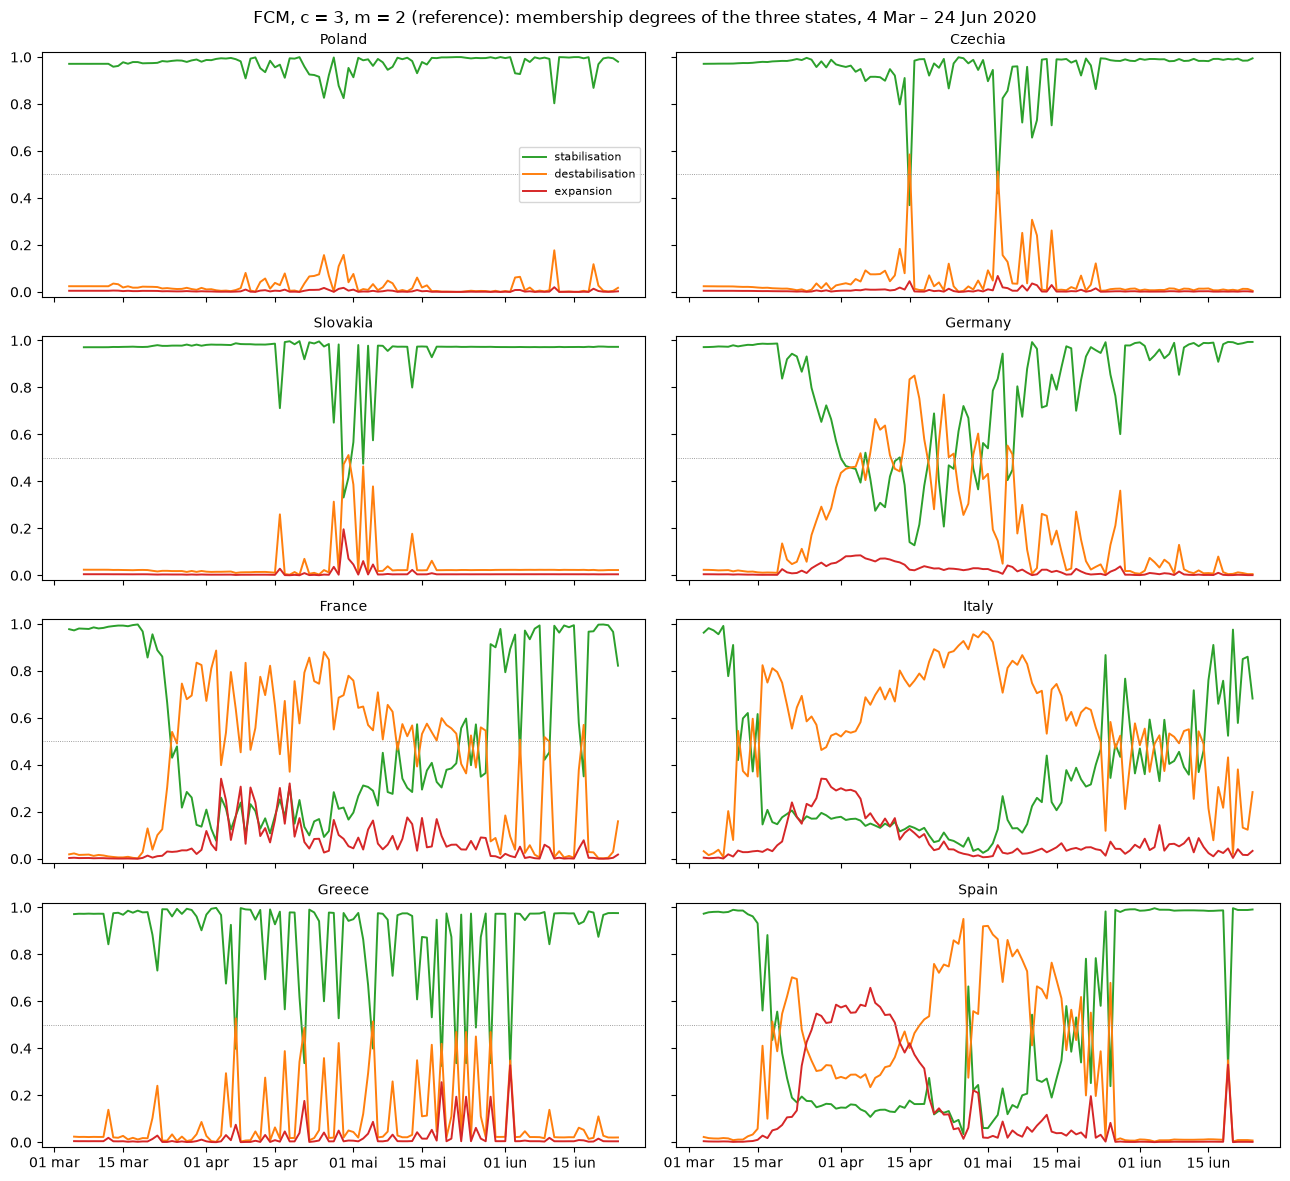

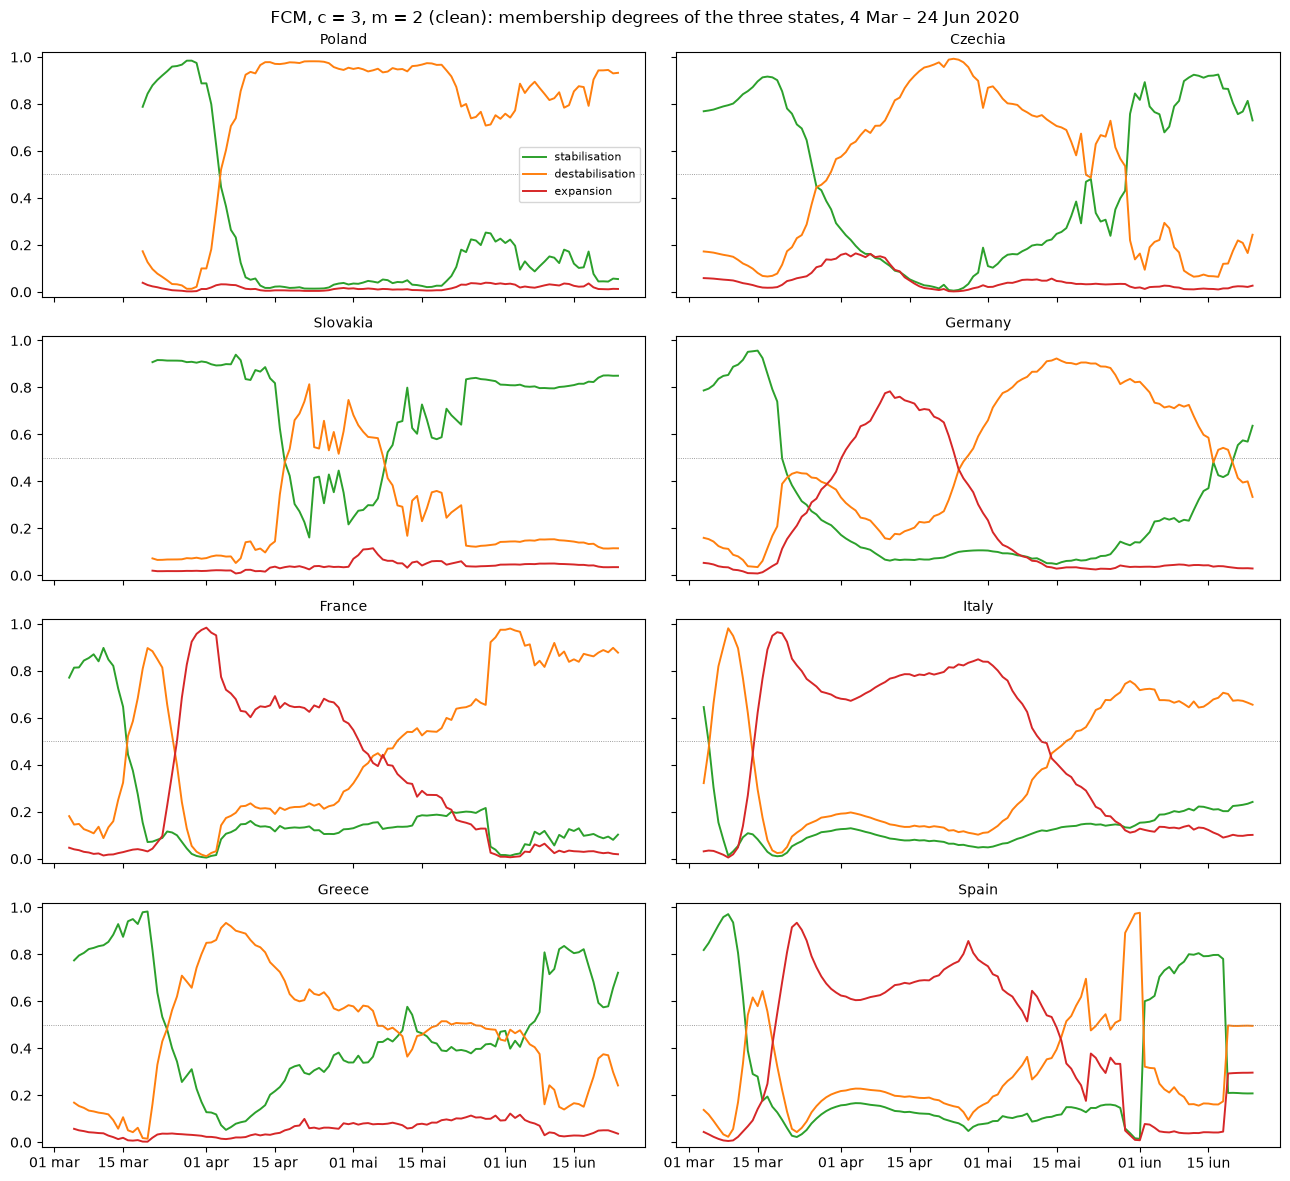

In [179]:
COLORS = {"stabilisation": "tab:green", "destabilisation": "tab:orange", "expansion": "tab:red"}
for name, R in results7.items():
    fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True, sharey=True)
    for ax, country in zip(axes.ravel(), FIG2_COUNTRIES):
        Rc = R[R["countriesAndTerritories"] == country]
        for s in STATE_NAMES:
            ax.plot(Rc["date"], Rc[f"u_{s}"], color=COLORS[s], label=s, lw=1.4)
        ax.axhline(0.5, color="grey", lw=0.6, ls=":")
        ax.set_title(country, fontsize=10)
        ax.set_ylim(-0.02, 1.02)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    axes[0, 0].legend(fontsize=8, loc="center right")
    fig.suptitle(f"FCM, c = 3, m = 2 ({name}): membership degrees of the three states, 4 Mar – 24 Jun 2020")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"covid_c3_{name}_memberships_8countries.png", dpi=200)
    plt.show()

### 7d: Normalised entropy per country (Figure 5, eq. 8) and daily entropy (Figure 6, eq. 10)

eq. (8): H_i = (1/T) Σ_t Σ_g −u_tig log_G u_tig. T = number of days the country has in the variant
(the paper writes T = 113 for all; countries that start later have fewer days).

Figure 5 countries:
          paper  reference  clean
Italy      0.65       0.63   0.67
France     0.54       0.52   0.62
Spain      0.51       0.50   0.70
Germany    0.37       0.39   0.63
Greece     0.24       0.27   0.66
Czechia    0.15       0.16   0.53
Slovakia   0.14       0.16   0.56
Poland     0.09       0.11   0.32

rank correlation (Spearman) with the paper's order: {'paper': 1.0, 'reference': 1.0, 'clean': 0.76}

highest entropy, all countries:
                         reference  clean
countriesAndTerritories                  
San_Marino                    0.79    NaN
Belarus                       0.65   0.83
Andorra                       0.63    NaN
Italy                         0.63   0.67
Belgium                       0.60   0.65
Holy_See                      0.57    NaN
Ireland                       0.55   0.60
Sweden                        0.53   0.44
France                        0.52   0.62
United_Kingdom                0.51   0.57

lowest entropy, all countries:
    

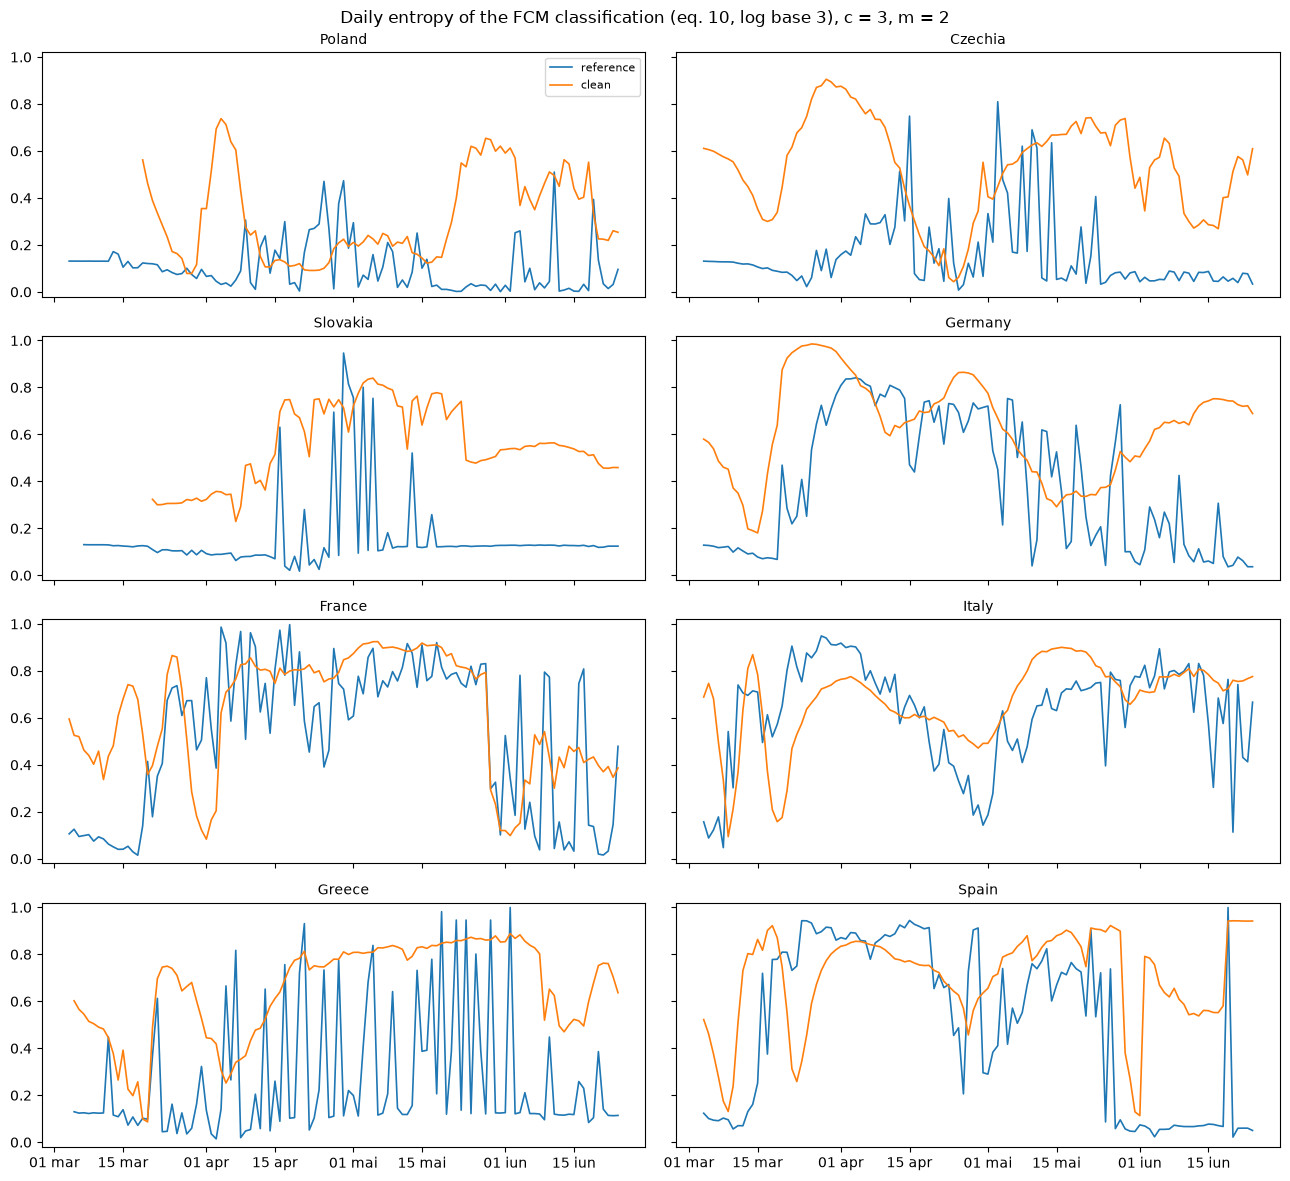

In [180]:
H_country = pd.DataFrame({name: R.groupby("countriesAndTerritories")["H_day"].mean() for name, R in results7.items()})
H_country.to_csv(OUT_DIR / "covid_fcm_c3_entropy_by_country.csv")
cmp5 = pd.concat([PAPER_FIG5, H_country.loc[PAPER_FIG5.index]], axis=1).round(3)
print("Figure 5 countries:"); print(cmp5)
print("\nrank correlation (Spearman) with the paper's order:", cmp5.corr(method="spearman")["paper"].round(2).to_dict())
print("\nhighest entropy, all countries:"); print(H_country.sort_values("reference", ascending=False).head(10).round(3))
print("\nlowest entropy, all countries:"); print(H_country.sort_values("reference").head(10).round(3))

fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True, sharey=True)
for ax, country in zip(axes.ravel(), FIG2_COUNTRIES):
    for name, R in results7.items():
        Rc = R[R["countriesAndTerritories"] == country]
        ax.plot(Rc["date"], Rc["H_day"], lw=1.2, label=name)
    ax.set_title(country, fontsize=10)
    ax.set_ylim(-0.02, 1.02)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0, 0].legend(fontsize=8)
fig.suptitle("Daily entropy of the FCM classification (eq. 10, log base 3), c = 3, m = 2")
fig.tight_layout()
fig.savefig(FIG_DIR / "covid_c3_daily_entropy_8countries.png", dpi=200)
plt.show()

### 7e: Reference vs clean: how often do the hard states agree (same country-day)?

In [181]:
both = results7["reference"][["countriesAndTerritories", "date", "state"]].merge(
    results7["clean"][["countriesAndTerritories", "date", "state"]], on=["countriesAndTerritories", "date"],
    suffixes=(" (reference)", " (clean)"))
print("common country-days:", len(both))
print("agreement:", round((both["state (reference)"] == both["state (clean)"]).mean(), 3))
pd.crosstab(both["state (reference)"], both["state (clean)"])

common country-days: 4786
agreement: 0.388


state (clean),destabilisation,expansion,stabilisation
state (reference),,,
destabilisation,281,627,7
expansion,0,140,0
stabilisation,2102,195,1434


## Step 8: Which change makes the difference? (one change at a time)

The clean variant changed four things at once (Step 5) and the FCM picture changed a lot (Step 7). Here we start from
the reference and apply **one** change at a time, then run the same FCM (c = 3, m = 2, 10 starts):

| variant | change w.r.t. the reference |
|---|---|
| reference | none (reproduces the paper) |
| 1 no microstates | drop entities with < 100,000 inhabitants |
| 2 drop missing x4 | drop rows with missing 14-day rate (instead of x4 = 0) |
| 3 7-day means | x1, x2 = mean of the last 7 reported days; x3 = deaths7 / cases7 × 100 (shorter window at the start) |
| 4 log1p | log1p of x1–x4 before the z-score |
| clean | all four |

What we compare:
- the class means of x4 (where the three states sit), share of country-days in each hard state;
- NPC and the mean normalised entropy (how fuzzy the partition is);
- entropy of the 8 countries of Figure 5 and its rank correlation with the paper;
- **roughness**: mean absolute day-to-day change of the memberships within a country (the zig-zag of Step 7).

In [182]:
def build_variant(drop_small=False, drop_missing_x4=False, smooth=False, log=False):
    b = eu_all[eu_all["date"].between(START, END)].copy()
    if drop_small:
        b = b[b["popData2019"] >= POP_MIN]
    if drop_missing_x4:
        b = b[b[RATE14].notna()]
    if smooth:
        cases = eu_all.groupby("countriesAndTerritories")["cases0"].transform(lambda s: s.rolling(7, min_periods=1).sum())
        deaths = eu_all.groupby("countriesAndTerritories")["deaths0"].transform(lambda s: s.rolling(7, min_periods=1).sum())
        n = eu_all.groupby("countriesAndTerritories")["cases0"].transform(lambda s: s.rolling(7, min_periods=1).count())
        cs, ds, nn = cases.loc[b.index], deaths.loc[b.index], n.loc[b.index]
    else:
        cs, ds, nn = b["cases0"], b["deaths0"], pd.Series(1, index=b.index)
    X = pd.DataFrame({"countriesAndTerritories": b["countriesAndTerritories"], "date": b["date"]})
    X["x1"] = cs / nn / b["popData2019"] * 1e5
    X["x2"] = ds / nn / b["popData2019"] * 1e5
    X["x3"] = np.where(cs > 0, ds / cs.where(cs > 0) * 100, 0.0)
    X["x4"] = b[RATE14].fillna(0.0)
    X = X.reset_index(drop=True)
    L = np.log1p(X[FEATS]) if log else X[FEATS]
    Z = ((L - L.mean()) / L.std(ddof=0)).to_numpy(dtype=float)
    return X, Z

ABLATION = {
    "reference":          dict(),
    "1 no microstates":   dict(drop_small=True),
    "2 drop missing x4":  dict(drop_missing_x4=True),
    "3 7-day means":      dict(smooth=True),
    "4 log1p":            dict(log=True),
}

def summarise_c3(name, X, Z):
    best, info = fcm.fcm_multistart(Z, C_PAPER, m=M_MAIN, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
    U = best.U.T
    order = np.argsort((U * X["x4"].to_numpy()[:, None]).sum(axis=0) / U.sum(axis=0))
    U = U[:, order]
    with np.errstate(divide="ignore", invalid="ignore"):
        H = -np.nansum(np.where(U > 0, U * np.log(U) / np.log(C_PAPER), 0.0), axis=1)
    R = X.copy()
    R["H"] = H
    for j, s in enumerate(STATE_NAMES):
        R[f"u_{s}"] = U[:, j]
    R["state"] = np.array(STATE_NAMES)[U.argmax(axis=1)]
    ucols = [f"u_{s}" for s in STATE_NAMES]
    rough = R.groupby("countriesAndTerritories")[ucols].apply(lambda g: g.diff().abs().sum(axis=1).mean()).mean()
    Hc = R.groupby("countriesAndTerritories")["H"].mean()
    row = {"variant": name, "rows": len(R), "countries": R["countriesAndTerritories"].nunique(),
           "starts at best J": info["n_at_best"], **fcm.validity_indices(Z, best, M_MAIN),
           "mean entropy": H.mean(), "roughness": rough,
           **{f"x4 mean {s}": (R[f"u_{s}"] * R["x4"]).sum() / R[f"u_{s}"].sum() for s in STATE_NAMES},
           **{f"% {s}": (R["state"] == s).mean() * 100 for s in STATE_NAMES},
           "Spearman H vs paper (8 countries)": pd.concat([PAPER_FIG5, Hc.reindex(PAPER_FIG5.index)], axis=1).corr(method="spearman").iloc[0, 1]}
    return row, R, Hc

abl_rows, abl_R, abl_H = [], {}, {}
for name, kw in ABLATION.items():
    X, Z = build_variant(**kw)
    row, R, Hc = summarise_c3(name, X, Z)
    abl_rows.append(row); abl_R[name] = R; abl_H[name] = Hc
row, R, Hc = summarise_c3("clean", clean, clean_z[FEATS].to_numpy(dtype=float))
abl_rows.append(row); abl_R["clean"] = R; abl_H["clean"] = Hc

ablation = pd.DataFrame(abl_rows).set_index("variant")
ablation.to_csv(OUT_DIR / "covid_c3_ablation.csv")
cols = ["rows", "countries", "NPC", "mean entropy", "roughness", "x4 mean stabilisation", "x4 mean destabilisation",
        "x4 mean expansion", "% stabilisation", "% destabilisation", "% expansion", "Spearman H vs paper (8 countries)"]
ablation[cols].round(2)

,rows,countries,NPC,mean entropy,roughness,x4 mean stabilisation,x4 mean destabilisation,x4 mean expansion,% stabilisation,% destabilisation,% expansion,Spearman H vs paper (8 countries)
variant,,,,,,,,,,,,
reference,5949,55,0.68,0.35,0.18,20.41,72.91,179.50,77.76,16.39,5.85,1.00
1 no microstates,5023,46,0.65,0.38,0.17,14.30,57.70,97.82,75.29,17.18,7.53,1.00
2 drop missing x4,5627,55,0.67,0.36,0.17,21.64,77.54,187.52,76.49,18.16,5.35,0.98
3 7-day means,5949,55,0.70,0.33,0.05,19.58,75.70,198.41,79.04,15.73,5.23,0.95
4 log1p,5949,55,0.44,0.60,0.29,18.38,38.06,90.69,40.66,41.49,17.85,0.90
clean,4786,46,0.42,0.62,0.08,14.32,23.75,75.23,30.11,49.79,20.10,0.76


### 8b: Entropy of the 8 countries of Figure 5, per variant

In [183]:
H8 = pd.concat([PAPER_FIG5] + [abl_H[k].reindex(PAPER_FIG5.index).rename(k) for k in abl_H], axis=1)
H8.to_csv(OUT_DIR / "covid_c3_ablation_entropy_8countries.csv")
H8.round(2)

,paper,reference,1 no microstates,2 drop missing x4,3 7-day means,4 log1p,clean
Italy,0.65,0.63,0.64,0.62,0.60,0.69,0.67
France,0.54,0.52,0.59,0.52,0.48,0.68,0.62
Spain,0.51,0.50,0.54,0.51,0.55,0.71,0.70
Germany,0.37,0.39,0.34,0.38,0.36,0.64,0.63
Greece,0.24,0.27,0.24,0.26,0.18,0.56,0.66
Czechia,0.15,0.16,0.21,0.16,0.11,0.54,0.53
Slovakia,0.14,0.16,0.18,0.17,0.13,0.38,0.56
Poland,0.09,0.11,0.09,0.09,0.05,0.44,0.32


### 8c: Agreement of the hard states with the reference (same country-days)

In [184]:
agree = {}
base_states = abl_R["reference"].set_index(["countriesAndTerritories", "date"])["state"]
for k, R in abl_R.items():
    s = R.set_index(["countriesAndTerritories", "date"])["state"]
    common = base_states.index.intersection(s.index)
    agree[k] = {"common country-days": len(common), "same state %": (base_states[common] == s[common]).mean() * 100}
pd.DataFrame(agree).T.round(1)

,common country-days,same state %
reference,5949.0,100.0
1 no microstates,5023.0,82.7
2 drop missing x4,5627.0,96.3
3 7-day means,5949.0,90.5
4 log1p,5949.0,50.8
clean,4786.0,38.8


## Step 9: c = 2 and c = 4 (the values supported by the indices in Step 6)

The paper fixes c = 3. In Step 6, KL's first local maximum was c = 2 for every variant, and NPC (and XB for the
control) preferred c = 4 on the log1p variants. Here we look at what these partitions mean, for the reference and the
clean variant, using the best FCM run of Step 6 (m = 2, 10 starts).

Classes are ordered by their membership-weighted mean of x4 and called L1 (lowest) ... Lc (highest), since the
paper's three names do not apply to c = 2 or 4. For each c: class means (raw units), share of country-days per hard
class, normalised entropy (log base c), and a crosstab against the c = 3 states, to see which states merge (c = 2)
or split (c = 4).

In [185]:
def partition_table(name, c):
    X = raw_frames[name]
    U = grid_runs[(name, c)].U.T
    order = np.argsort((U * X["x4"].to_numpy()[:, None]).sum(axis=0) / U.sum(axis=0))
    U = U[:, order]
    R = X[["countriesAndTerritories", "date"] + FEATS].copy()
    labels = [f"L{j + 1}" for j in range(c)]
    for j, l in enumerate(labels):
        R[f"u_{l}"] = U[:, j]
    R["level"] = np.array(labels)[U.argmax(axis=1)]
    with np.errstate(divide="ignore", invalid="ignore"):
        R["H_day"] = -np.nansum(np.where(U > 0, U * np.log(U) / np.log(c), 0.0), axis=1)
    return R, labels

part = {}
means_rows = []
for name in ["reference", "clean"]:
    for c in (2, 3, 4):
        R, labels = partition_table(name, c)
        part[(name, c)] = (R, labels)
        for l in labels:
            u = R[f"u_{l}"]
            means_rows.append({"variant": name, "c": c, "class": l,
                               **{f: (u * R[f]).sum() / u.sum() for f in FEATS},
                               "% country-days (hard)": (R["level"] == l).mean() * 100})
        print(f"{name:10s} c={c}: NPC = {fcm.normalized_partition_coefficient(grid_runs[(name, c)].U):.3f}, "
              f"mean entropy = {R['H_day'].mean():.3f}")
class_means = pd.DataFrame(means_rows)
class_means.to_csv(OUT_DIR / "covid_c234_class_means.csv", index=False)
class_means.set_index(["variant", "c", "class"]).round(2)

reference  c=2: NPC = 0.727, mean entropy = 0.324
reference  c=3: NPC = 0.676, mean entropy = 0.352
reference  c=4: NPC = 0.620, mean entropy = 0.385
clean      c=2: NPC = 0.446, mean entropy = 0.627
clean      c=3: NPC = 0.416, mean entropy = 0.616
clean      c=4: NPC = 0.449, mean entropy = 0.567


x1    x2     x3      x4  % country-days (hard)
variant   c class                                                   
reference 2 L1      1.97  0.08   4.53   25.18                  86.65
            L2      9.27  0.58  14.64  125.66                  13.35
          3 L1      1.63  0.06   3.46   20.41                  77.76
            L2      5.36  0.40  14.68   72.91                  16.39
            L3     13.27  0.60  12.65  179.50                   5.85
          4 L1      1.36  0.05   2.94   16.67                  66.83
            L2      4.26  0.22  10.08   57.51                  22.41
            L3      7.46  0.73  19.09   99.31                   6.35
            L4     14.56  0.50  11.08  200.04                   4.40
clean     2 L1      1.20  0.06   5.99   16.07                  66.84
            L2      4.14  0.27   8.75   56.74                  33.16
          3 L1      1.11  0.05   4.08   14.32                  30.11
            L2      1.72  0.10   8.04   23.75                  49.79
            L3      5.48  0.39   9.73   75.23                  20.10
          4 L1      0.86  0.03   3.31   11.06                  25.74
            L2      1.21  0.08   8.97   17.08                  40.53
            L3      3.83  0.13   5.23   50.45                  24.09
            L4      5.75  0.62  13.50   81.40                   9.63

### 9a: How the c = 3 states map onto c = 2 and c = 4 (hard assignments, same country-days)

In [186]:
for name in ["reference", "clean"]:
    s3 = results7[name]["state"].to_numpy()
    for c in (2, 4):
        R, _ = part[(name, c)]
        print(f"\n{name}, c = 3 (rows) vs c = {c} (columns), % of all country-days:")
        print((pd.crosstab(s3, R["level"].to_numpy(), normalize=True) * 100).round(1).reindex(STATE_NAMES))


reference, c = 3 (rows) vs c = 2 (columns), % of all country-days:
col_0              L1   L2
row_0                     
stabilisation    77.8  0.0
destabilisation   8.9  7.5
expansion         0.0  5.8

reference, c = 3 (rows) vs c = 4 (columns), % of all country-days:
col_0              L1    L2   L3   L4
row_0                                
stabilisation    66.8  10.9  0.0  0.0
destabilisation   0.0  11.3  5.1  0.0
expansion         0.0   0.2  1.2  4.4

clean, c = 3 (rows) vs c = 2 (columns), % of all country-days:
col_0              L1    L2
row_0                      
stabilisation    30.1   0.0
destabilisation  36.7  13.1
expansion         0.0  20.1

clean, c = 3 (rows) vs c = 4 (columns), % of all country-days:
col_0              L1    L2    L3   L4
row_0                                 
stabilisation    25.7   3.3   1.1  0.0
destabilisation   0.0  37.1  12.6  0.0
expansion         0.0   0.1  10.3  9.6


### 9b: Memberships over time, c = 2 and c = 4, for the 8 countries

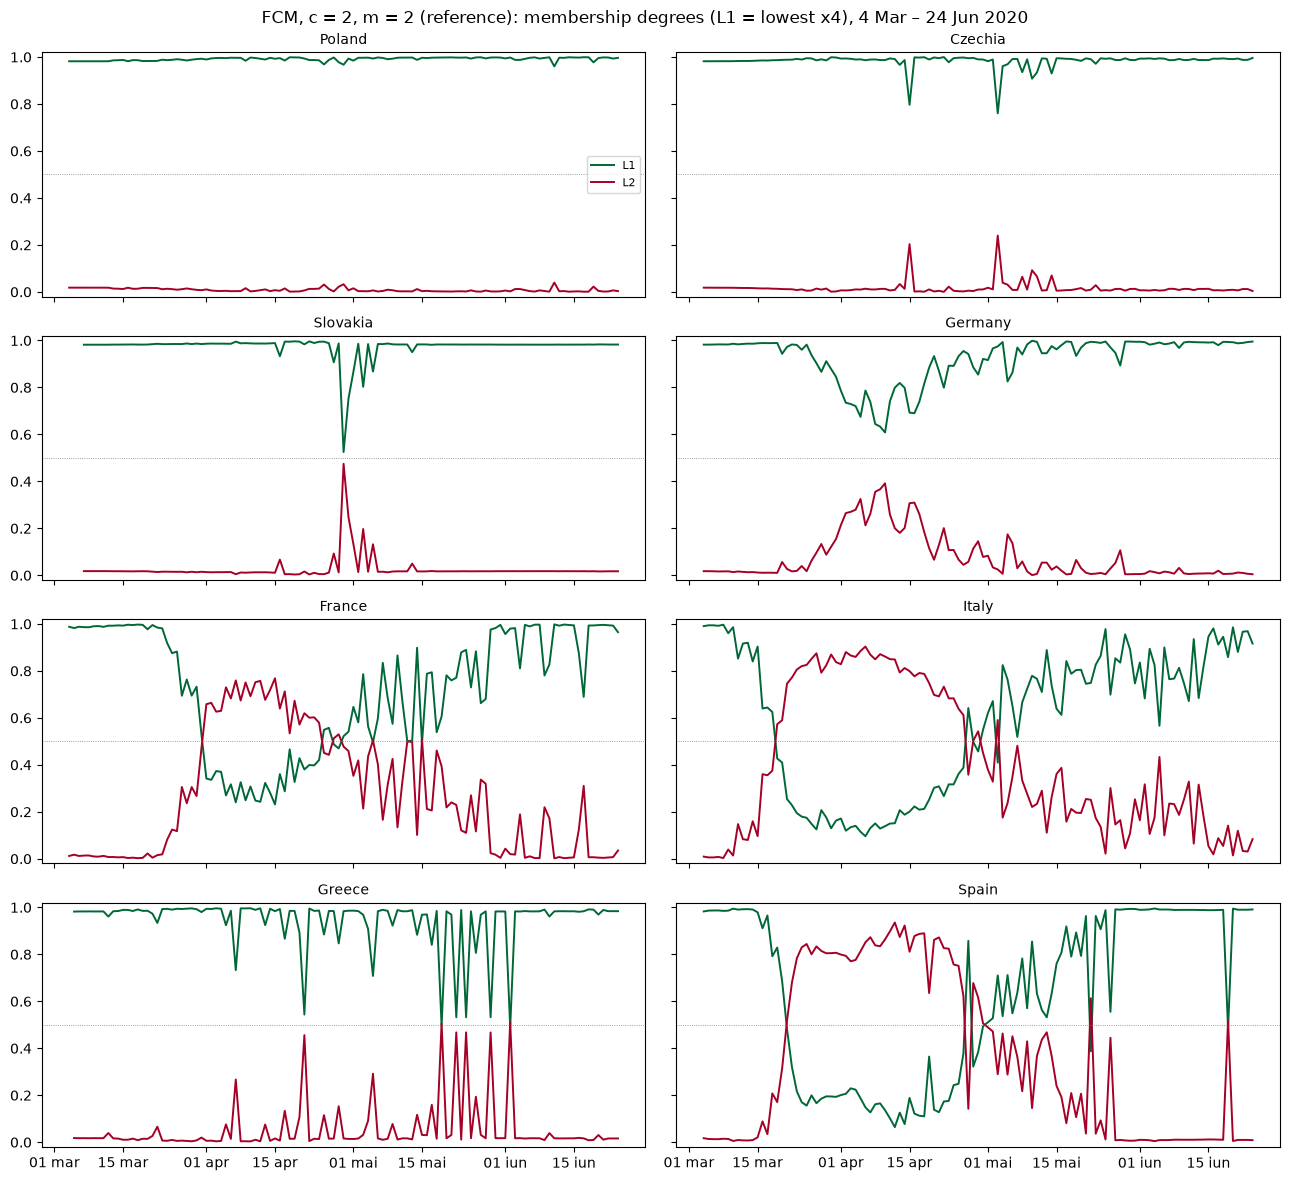

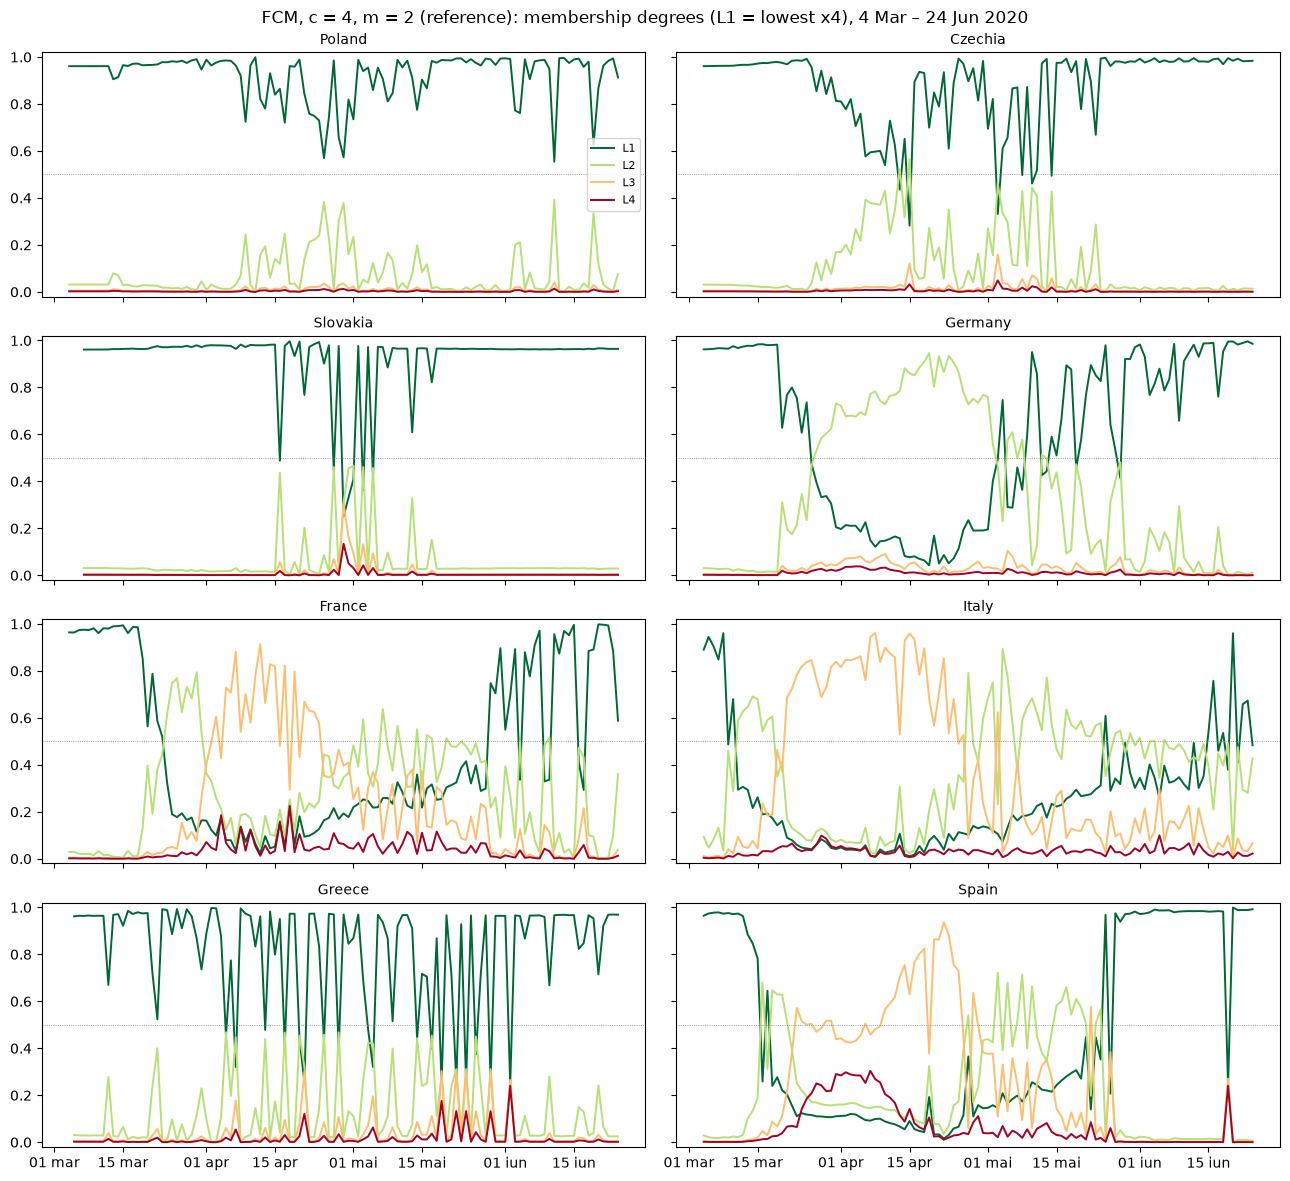

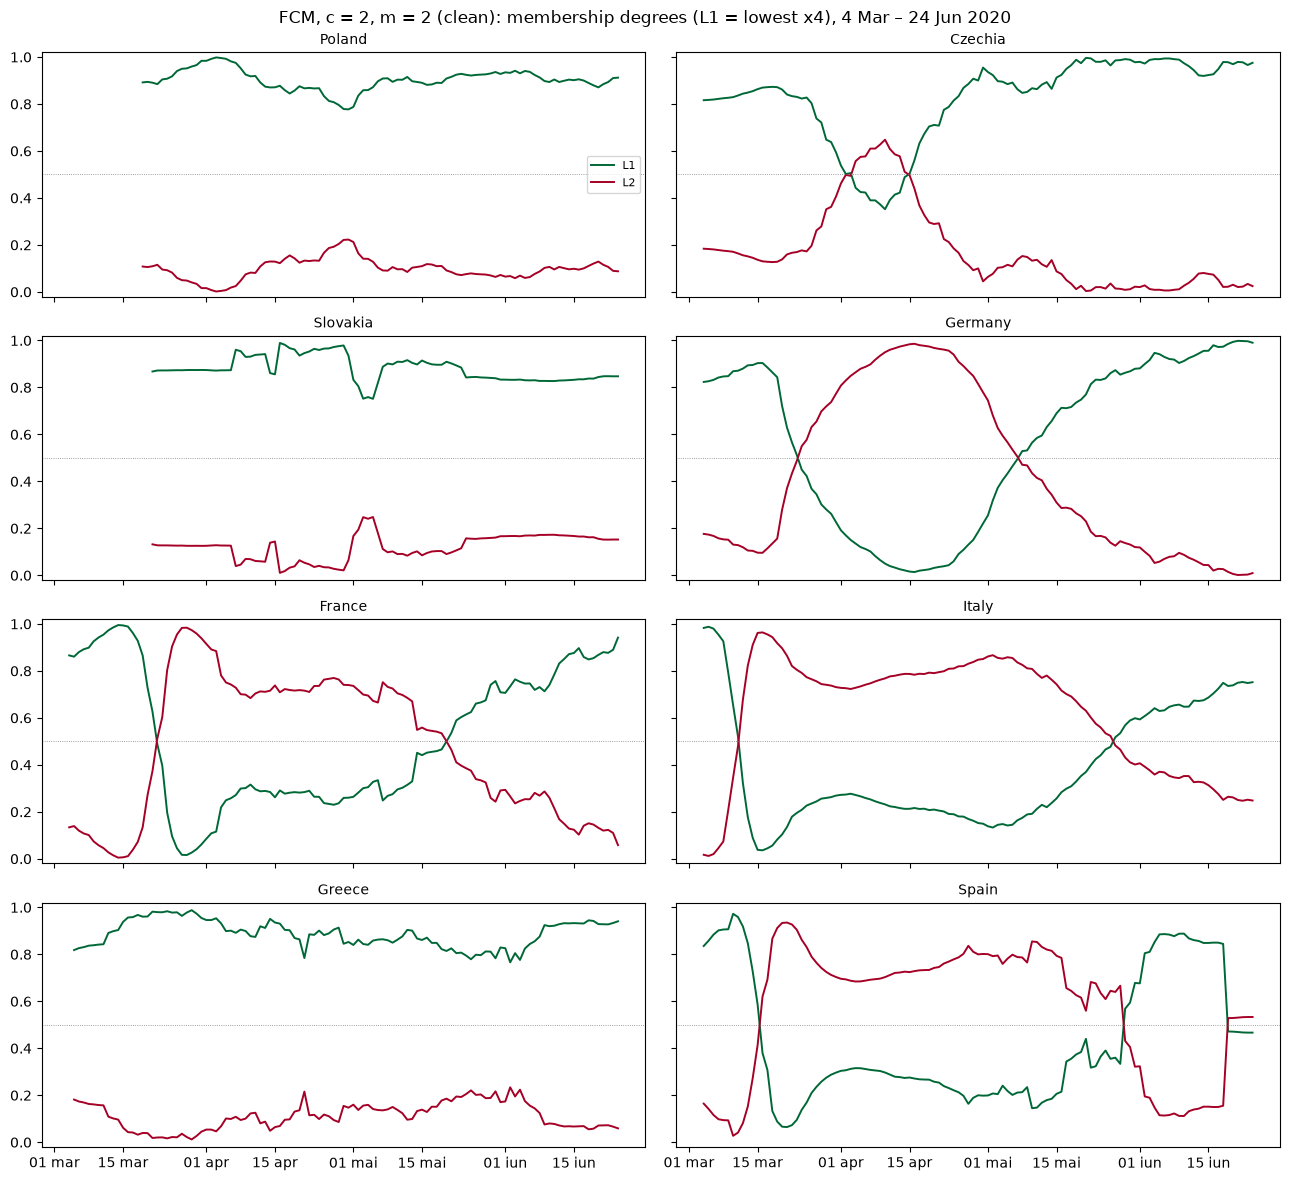

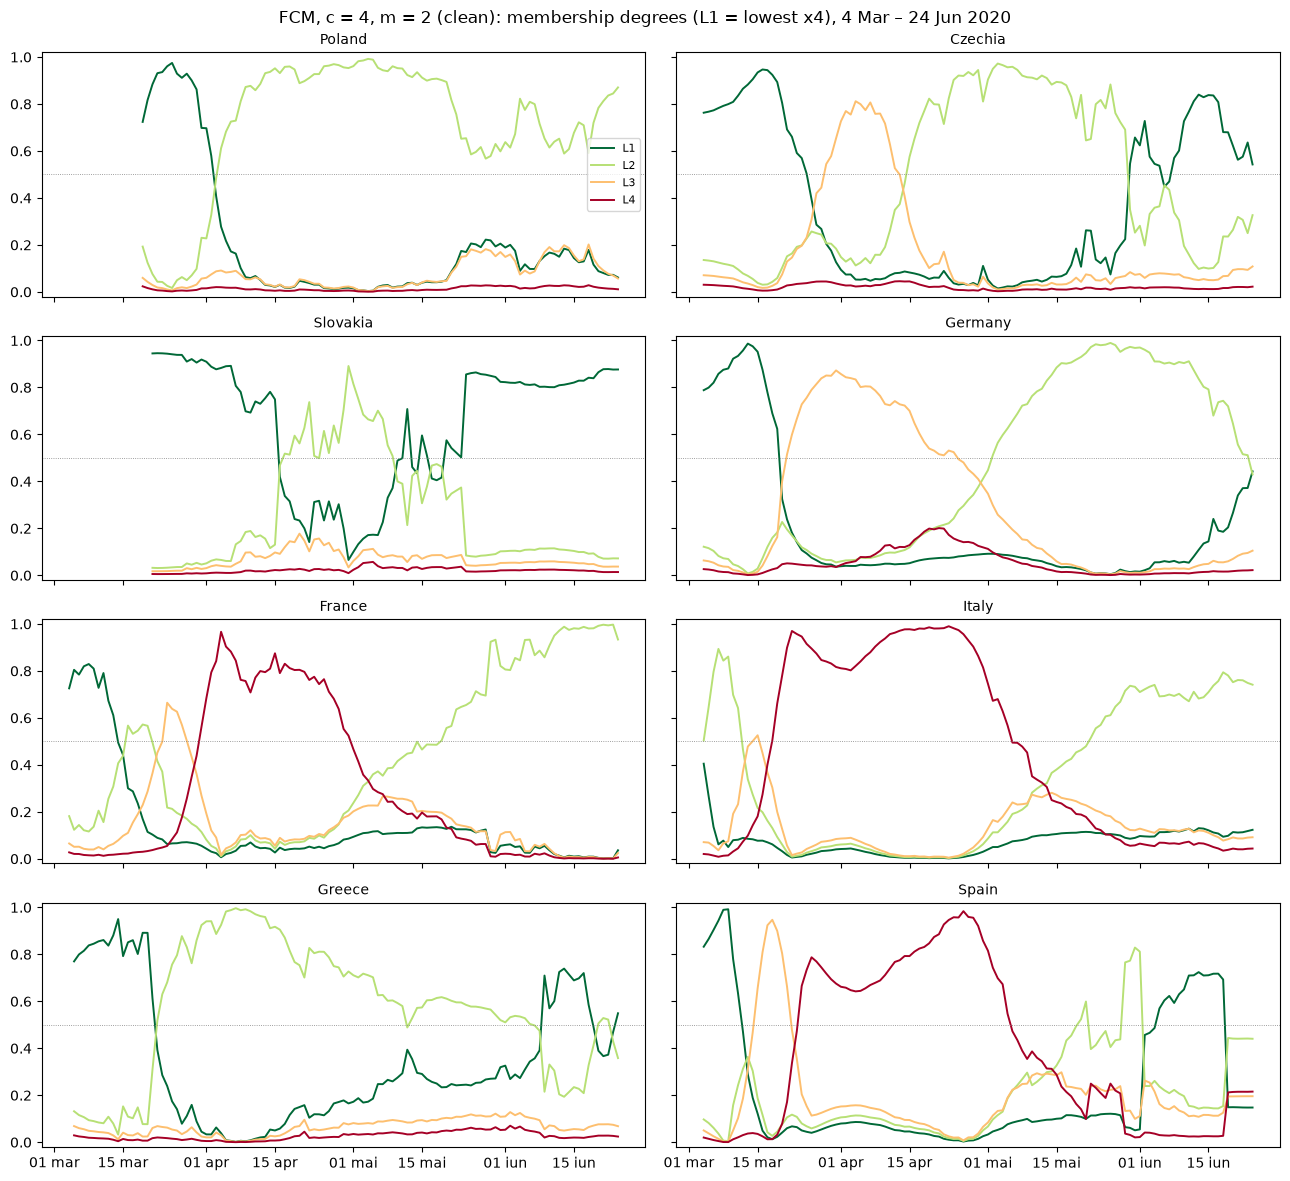

In [187]:
for name in ["reference", "clean"]:
    for c in (2, 4):
        R, labels = part[(name, c)]
        cmap = plt.get_cmap("RdYlGn_r")
        colors = [cmap(j / (c - 1)) for j in range(c)]
        fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True, sharey=True)
        for ax, country in zip(axes.ravel(), FIG2_COUNTRIES):
            Rc = R[R["countriesAndTerritories"] == country]
            for l, col in zip(labels, colors):
                ax.plot(Rc["date"], Rc[f"u_{l}"], color=col, label=l, lw=1.4)
            ax.axhline(0.5, color="grey", lw=0.6, ls=":")
            ax.set_title(country, fontsize=10)
            ax.set_ylim(-0.02, 1.02)
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        axes[0, 0].legend(fontsize=8, loc="center right")
        fig.suptitle(f"FCM, c = {c}, m = 2 ({name}): membership degrees (L1 = lowest x4), 4 Mar – 24 Jun 2020")
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"covid_c{c}_{name}_memberships_8countries.png", dpi=200)
        plt.show()

### 9c: Entropy of the 8 countries for c = 2, 3, 4

In [188]:
H_c = pd.concat([PAPER_FIG5] + [part[(n, c)][0].groupby("countriesAndTerritories")["H_day"].mean()
                                 .reindex(PAPER_FIG5.index).rename(f"{n} c={c}")
                                 for n in ["reference", "clean"] for c in (2, 3, 4)], axis=1)
H_c.to_csv(OUT_DIR / "covid_c234_entropy_8countries.csv")
print("Spearman with the paper:", H_c.corr(method="spearman")["paper"].round(2).to_dict())
H_c.round(2)

Spearman with the paper: {'paper': 1.0, 'reference c=2': 0.98, 'reference c=3': 1.0, 'reference c=4': 0.98, 'clean c=2': 0.9, 'clean c=3': 0.76, 'clean c=4': 0.74}


,paper,reference c=2,reference c=3,reference c=4,clean c=2,clean c=3,clean c=4
Italy,0.65,0.66,0.63,0.62,0.76,0.67,0.56
France,0.54,0.56,0.52,0.57,0.71,0.62,0.58
Spain,0.51,0.49,0.50,0.52,0.74,0.70,0.65
Germany,0.37,0.30,0.39,0.37,0.56,0.63,0.49
Greece,0.24,0.21,0.27,0.31,0.48,0.66,0.55
Czechia,0.15,0.10,0.16,0.24,0.52,0.53,0.50
Slovakia,0.14,0.15,0.16,0.17,0.51,0.56,0.52
Poland,0.09,0.06,0.11,0.19,0.44,0.32,0.41


### 9d: Who is in the two highest classes at c = 4?

At c = 4 the two highest classes differ mainly in x2/x3 (mortality) rather than in x4 (incidence). Which countries
and which months do they contain?

In [189]:
for name in ["reference", "clean"]:
    R, labels = part[(name, 4)]
    for l in ["L3", "L4"]:
        s = R[R["level"] == l]
        print(f"{name} {l}: {len(s)} country-days, median date {s['date'].median().date()}, "
              f"by month {s['date'].dt.month.value_counts(normalize=True).sort_index().round(2).to_dict()}")
        print("   top countries:", s["countriesAndTerritories"].value_counts().head(8).to_dict())

reference L3: 378 country-days, median date 2020-04-19, by month {3: 0.11, 4: 0.66, 5: 0.2, 6: 0.03}
   top countries: {'Belgium': 45, 'Italy': 41, 'Spain': 41, 'United_Kingdom': 38, 'Sweden': 36, 'France': 32, 'Netherlands': 21, 'Jersey': 17}
reference L4: 262 country-days, median date 2020-04-11, by month {3: 0.21, 4: 0.56, 5: 0.14, 6: 0.1}
   top countries: {'San_Marino': 58, 'Holy_See': 40, 'Andorra': 27, 'Armenia': 26, 'Luxembourg': 22, 'Iceland': 20, 'Faroe_Islands': 17, 'Guernsey': 13}
clean L3: 1153 country-days, median date 2020-04-21, by month {3: 0.18, 4: 0.42, 5: 0.2, 6: 0.2}
   top countries: {'Portugal': 94, 'Moldova': 81, 'Belarus': 76, 'Armenia': 71, 'Russia': 69, 'Turkey': 61, 'Denmark': 49, 'Iceland': 46}
clean L4: 461 country-days, median date 2020-04-21, by month {3: 0.08, 4: 0.62, 5: 0.3, 6: 0.0}
   top countries: {'United_Kingdom': 60, 'Sweden': 59, 'Italy': 57, 'Belgium': 55, 'Spain': 53, 'Netherlands': 41, 'France': 36, 'Ireland': 36}


## Step 10: Sensitivity to the fuzzifier m

The paper does not report m (Step 0: `fclust::FKM` default m = 2). m controls how fuzzy the partition is: m → 1 gives
a hard (k-means-like) partition, larger m spreads the memberships. So entropy is *expected* to grow with m; the
questions are whether the **states themselves** (prototypes, hard assignment) and the **ranking of the countries**
by entropy (the paper's Figure 5) survive a change of m.

Grid: m ∈ {1.25, 1.5, 1.75, 2, 2.5} (1.5 = (2 + p)/p for p = 4, Winkler et al. 2011, as for the other datasets),
c ∈ {3, 4}, reference and clean variant, 10 starts each. For each run: NPC, mean entropy, number of distinct
prototypes, class means of x4, hard-state agreement with m = 2 (same c, classes ordered by x4), and the Spearman
correlation of the 8 countries' entropy with the paper.

In [190]:
M_GRID = [1.25, 1.5, 1.75, 2.0, 2.5]
m_rows, m_states = [], {}
t0 = time.time()
for name in ["reference", "clean"]:
    A = data[name]
    X = raw_frames[name]
    for c in (3, 4):
        for m in M_GRID:
            best, info = (grid_runs[(name, c)], {"n_at_best": None}) if m == M_MAIN else \
                fcm.fcm_multistart(A, c, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            U = best.U.T
            order = np.argsort((U * X["x4"].to_numpy()[:, None]).sum(axis=0) / U.sum(axis=0))
            U = U[:, order]
            with np.errstate(divide="ignore", invalid="ignore"):
                H = -np.nansum(np.where(U > 0, U * np.log(U) / np.log(c), 0.0), axis=1)
            Hc = pd.Series(H, index=X.index).groupby(X["countriesAndTerritories"]).mean()
            m_states[(name, c, m)] = U.argmax(axis=1)
            m_rows.append({"variant": name, "c": c, "m": m,
                           "NPC": fcm.normalized_partition_coefficient(best.U), "mean entropy": H.mean(),
                           "n_distinct": fcm.prototype_diagnostics(A, best)["n_distinct"],
                           "starts at best J": info["n_at_best"],
                           "x4 class means": np.round((U * X["x4"].to_numpy()[:, None]).sum(axis=0) / U.sum(axis=0), 1).tolist(),
                           "Spearman H vs paper": pd.concat([PAPER_FIG5, Hc.reindex(PAPER_FIG5.index)], axis=1)
                                                    .corr(method="spearman").iloc[0, 1],
                           "Poland H": Hc.get("Poland"), "Italy H": Hc.get("Italy")})
        print(f"{name} c={c} done ({time.time() - t0:.0f} s)")
m_sens = pd.DataFrame(m_rows)
m_sens["same hard state as m=2 (%)"] = [
    (m_states[(r.variant, r.c, r.m)] == m_states[(r.variant, r.c, M_MAIN)]).mean() * 100 for r in m_sens.itertuples()]
m_sens.to_csv(OUT_DIR / "covid_m_sensitivity.csv", index=False)
m_sens.set_index(["variant", "c", "m"]).round(3)

reference c=3 done (3 s)
reference c=4 done (12 s)
clean c=3 done (14 s)
clean c=4 done (16 s)


NPC  mean entropy  n_distinct  starts at best J  \
variant   c m                                                        
reference 3 1.25  0.96          0.04           3               3.0   
            1.50  0.86          0.15           3              10.0   
            1.75  0.77          0.25           3              10.0   
            2.00  0.68          0.35           3               NaN   
            2.50  0.49          0.55           3              10.0   
          4 1.25  0.93          0.07           4               5.0   
            1.50  0.85          0.15           4               7.0   
            1.75  0.75          0.25           4               8.0   
            2.00  0.62          0.39           4               NaN   
            2.50  0.44          0.57           4              10.0   
clean     3 1.25  0.86          0.14           3               7.0   
            1.50  0.70          0.32           3              10.0   
            1.75  0.55          0.48           3              10.0   
            2.00  0.42          0.62           3               NaN   
            2.50  0.24          0.79           3              10.0   
          4 1.25  0.89          0.11           4              10.0   
            1.50  0.75          0.26           4              10.0   
            1.75  0.59          0.42           4              10.0   
            2.00  0.45          0.57           4               NaN   
            2.50  0.25          0.76           4              10.0   

                              x4 class means  Spearman H vs paper  Poland H  \
variant   c m                                                                 
reference 3 1.25         [24.1, 89.0, 240.0]                 0.88  0.00e+00   
            1.50         [21.2, 81.5, 264.4]                 0.95  4.00e-03   
            1.75         [20.4, 78.5, 221.4]                 0.95  3.60e-02   
            2.00         [20.4, 72.9, 179.5]                 1.00  1.06e-01   
            2.50         [21.3, 62.6, 121.2]                 1.00  3.23e-01   
          4 1.25  [17.5, 77.3, 103.2, 340.7]                 0.91  0.00e+00   
            1.50  [19.2, 62.0, 228.6, 233.5]                 0.91  9.00e-03   
            1.75  [18.2, 59.2, 165.9, 202.2]                 1.00  6.50e-02   
            2.00   [16.7, 57.5, 99.3, 200.0]                 0.98  1.86e-01   
            2.50   [18.3, 47.5, 82.1, 138.0]                 0.93  4.51e-01   
clean     3 1.25           [6.5, 17.4, 96.6]                 0.36  2.00e-02   
            1.50           [8.8, 20.9, 93.7]                 0.52  8.70e-02   
            1.75          [11.7, 22.8, 85.0]                 0.67  1.96e-01   
            2.00          [14.3, 23.7, 75.2]                 0.76  3.20e-01   
            2.50          [18.4, 25.0, 60.4]                 0.81  5.41e-01   
          4 1.25     [5.5, 12.6, 66.2, 99.8]                 0.48  4.90e-02   
            1.50     [6.4, 13.7, 62.3, 98.4]                 0.64  1.62e-01   
            1.75     [8.5, 15.3, 56.4, 91.1]                 0.74  2.85e-01   
            2.00    [11.1, 17.1, 50.4, 81.4]                 0.74  4.08e-01   
            2.50    [15.8, 20.2, 41.8, 65.9]                 0.76  6.18e-01   

                  Italy H  same hard state as m=2 (%)  
variant   c m                                          
reference 3 1.25     0.13                       84.10  
            1.50     0.30                       92.69  
            1.75     0.47                       96.86  
            2.00     0.63                      100.00  
            2.50     0.83                       93.78  
          4 1.25     0.10                       75.24  
            1.50     0.29                       75.73  
            1.75     0.49                       86.03  
            2.00     0.62                      100.00  
            2.50     0.79                       92.70  
clean     3 1.25     0.09                       96.34  
           

## Step 11: External validation: do the FCM states match what really happened?

Stefan's question (19 Nov 2026): are statements like "Poland was the most stable" true, and can they be checked
against reality? **The paper does no external validation**: its states are defined only from the reported
indicators (Section 3), and the hypothesis "the situation in Poland was stable" is "verified" with the same FCM
output. Reported cases and deaths depend on testing and on how deaths are attributed, so we compare the FCM results
with independent sources (Our World in Data, CC BY 4.0; downloaded with `get_external_data.py`):

1. **Excess mortality** (deaths from all causes above the 2015–2019 projected baseline; HMD/STMF, World Mortality
   Dataset, Eurostat): does not depend on testing or on cause-of-death coding. Main "ground truth".
2. **Testing**: tests per 1,000 inhabitants by 24 June and the mean positivity rate. A "stable" country with few tests
   and high positivity may simply have seen fewer of its cases.
3. **Stringency index** (Oxford COVID-19 Government Response Tracker): how strict the measures were.
4. **Out of sample**: the autumn 2020 wave (October–December), not used by the paper or by FCM.

Country-level FCM summaries (c = 3, m = 2, Step 7), for reference and clean:
- `% stabilisation`: share of the country's days in the stabilisation state (hard);
- `severity`: mean over days of 0·u_stab + 1·u_destab + 2·u_exp (0 = always stable, 2 = always expansion);
- `entropy`: the paper's eq. (8).

Windows: weekly excess data are summed over the weeks ending 8 March – 28 June 2020 (≈ 4 March – 24 June);
for countries with only monthly data, March–June. Autumn: weeks ending 4 October – 27 December, or October–December.
Correlations are Spearman (n ≈ 40–50 countries); p-values from a permutation test (10,000 shuffles, seed 42).

In [191]:
EXT_DIR = DATA_DIR / "external"
owid = pd.read_csv(EXT_DIR / "owid_daily_europe_2020.csv", parse_dates=["date"])
excess = pd.read_csv(EXT_DIR / "owid_excess_mortality_europe_2020.csv", parse_dates=["date"])
print("OWID daily:", owid.shape, "| excess mortality:", excess.shape,
      excess.groupby("time_unit")["countriesAndTerritories"].nunique().to_dict())

def excess_in(ex, w_from, w_to, months):
    weekly = ex[(ex["time_unit"] == "weekly") & ex["date"].between(w_from, w_to)]
    monthly = ex[(ex["time_unit"] == "monthly") & ex["date"].dt.year.eq(2020) & ex["date"].dt.month.isin(months)]
    both = pd.concat([weekly, monthly])
    return both.groupby("countriesAndTerritories").agg(
        excess_per_million=("excess_per_million_proj_all_ages", "sum"),
        mean_p_score=("p_proj_all_ages", "mean"), unit=("time_unit", "first"))

spring = excess_in(excess, "2020-03-08", "2020-06-28", [3, 4, 5, 6]).add_prefix("spring ")
autumn = excess_in(excess, "2020-10-04", "2020-12-27", [10, 11, 12]).add_prefix("autumn ")

w = owid[owid["date"].between(START, END)]
tests = w.dropna(subset=["total_tests_per_thousand"]).sort_values("date").groupby("countriesAndTerritories")["total_tests_per_thousand"].last()
ext = pd.concat([spring, autumn,
                 tests.rename("tests per 1000 by 24 Jun"),
                 w.groupby("countriesAndTerritories")["positive_rate"].mean().mul(100).rename("mean positivity %"),
                 w.groupby("countriesAndTerritories")["stringency_index"].mean().rename("mean stringency")], axis=1)

# reported COVID-19 deaths and cases per million from our ECDC file (negatives set to 0), same spring window, and autumn cases
eu_w = eu_all[eu_all["date"].between(START, END)]
pop = eu_all.groupby("countriesAndTerritories")["popData2019"].first()
ext["reported deaths per million (spring)"] = eu_w.groupby("countriesAndTerritories")["deaths0"].sum() / pop * 1e6
eu_aut = eu_all[eu_all["date"].between("2020-10-01", "2020-12-14")]
ext["reported cases per 100k (1 Oct-14 Dec)"] = eu_aut.groupby("countriesAndTerritories")["cases0"].sum() / pop * 1e5
ext.index.name = "countriesAndTerritories"
print("countries with spring excess data:", int(ext["spring excess_per_million"].notna().sum()))

OWID daily: (19910, 12) | excess mortality: (1956, 10) {'monthly': 19, 'weekly': 32}
countries with spring excess data: 51


### 11a: Country-level FCM summaries

In [192]:
def country_summary(R):
    sev = R["u_destabilisation"] * 1 + R["u_expansion"] * 2
    g = R.assign(severity=sev, stab=(R["state"] == "stabilisation")).groupby("countriesAndTerritories")
    return pd.DataFrame({"% stabilisation": g["stab"].mean() * 100, "severity": g["severity"].mean(),
                         "entropy": g["H_day"].mean()})

summ = {name: country_summary(R) for name, R in results7.items()}
val = {name: s.join(ext, how="left") for name, s in summ.items()}
for name, V in val.items():
    V.to_csv(OUT_DIR / f"covid_validation_{name}.csv")
val["reference"].loc[FIG2_COUNTRIES, ["% stabilisation", "severity", "entropy", "spring excess_per_million",
                                      "reported deaths per million (spring)", "tests per 1000 by 24 Jun",
                                      "mean positivity %", "autumn excess_per_million"]].round(1)

,% stabilisation,severity,entropy,spring excess_per_million,reported deaths per million (spring),tests per 1000 by 24 Jun,mean positivity %,autumn excess_per_million
countriesAndTerritories,,,,,,,,
Poland,100.0,0.0,0.1,-23.3,36.2,30.2,3.4,1555.4
Czechia,98.2,0.1,0.2,-11.2,31.8,8.0,2.0,1436.1
Slovakia,98.2,0.1,0.2,1.1,5.1,37.6,1.6,895.8
Germany,81.4,0.3,0.4,36.6,107.4,64.2,4.5,384.1
France,43.4,0.5,0.5,386.8,443.5,22.5,1.5,443.0
Italy,23.9,0.7,0.6,883.1,573.6,86.2,8.4,845.5
Greece,92.9,0.1,0.3,-1.2,17.7,27.9,2.5,434.7
Spain,45.1,0.6,0.5,1022.2,644.4,64.8,11.8,380.7


### 11b: Spearman correlations between the FCM summaries and the external indicators

In [193]:
def perm_spearman(x, y, n_perm=10_000, seed=SEED):
    ok = x.notna() & y.notna()
    rx, ry = x[ok].rank().to_numpy(), y[ok].rank().to_numpy()
    rho = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(seed)
    null = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(n_perm)])
    return rho, (np.abs(null) >= abs(rho)).mean(), int(ok.sum())

TARGETS = ["spring excess_per_million", "spring mean_p_score", "reported deaths per million (spring)",
           "tests per 1000 by 24 Jun", "mean positivity %", "mean stringency",
           "autumn excess_per_million", "reported cases per 100k (1 Oct-14 Dec)"]
corr_rows = []
for name, V in val.items():
    for f in ["severity", "% stabilisation", "entropy"]:
        for t in TARGETS:
            rho, p, n = perm_spearman(V[f], V[t])
            corr_rows.append({"variant": name, "FCM summary": f, "external": t, "rho": rho, "p": p, "n": n})
corr = pd.DataFrame(corr_rows)
corr.to_csv(OUT_DIR / "covid_validation_correlations.csv", index=False)
corr[corr["FCM summary"] == "severity"].pivot(index="external", columns="variant", values=["rho", "p", "n"]).round(3)

rho               p            \
variant                                    clean reference clean reference   
external                                                                     
autumn excess_per_million              -1.57e-01     -0.31  0.30      0.03   
mean positivity %                       4.15e-01      0.21  0.01      0.20   
mean stringency                        -7.00e-03     -0.20  0.96      0.18   
reported cases per 100k (1 Oct-14 Dec)  1.01e-01      0.06  0.50      0.69   
reported deaths per million (spring)    9.51e-01      0.70  0.00      0.00   
spring excess_per_million               6.04e-01      0.60  0.00      0.00   
spring mean_p_score                     6.09e-01      0.60  0.00      0.00   
tests per 1000 by 24 Jun                1.63e-01      0.38  0.33      0.02   

                                           n            
variant                                clean reference  
external                                                
autumn excess_per_million               45.0      51.0  
mean positivity %                       36.0      37.0  
mean stringency                         42.0      46.0  
reported cases per 100k (1 Oct-14 Dec)  46.0      55.0  
reported deaths per million (spring)    46.0      55.0  
spring excess_per_million               45.0      51.0  
spring mean_p_score                     45.0      51.0  
tests per 1000 by 24 Jun                38.0      39.0

### 11c: Severity vs excess mortality (spring and autumn)

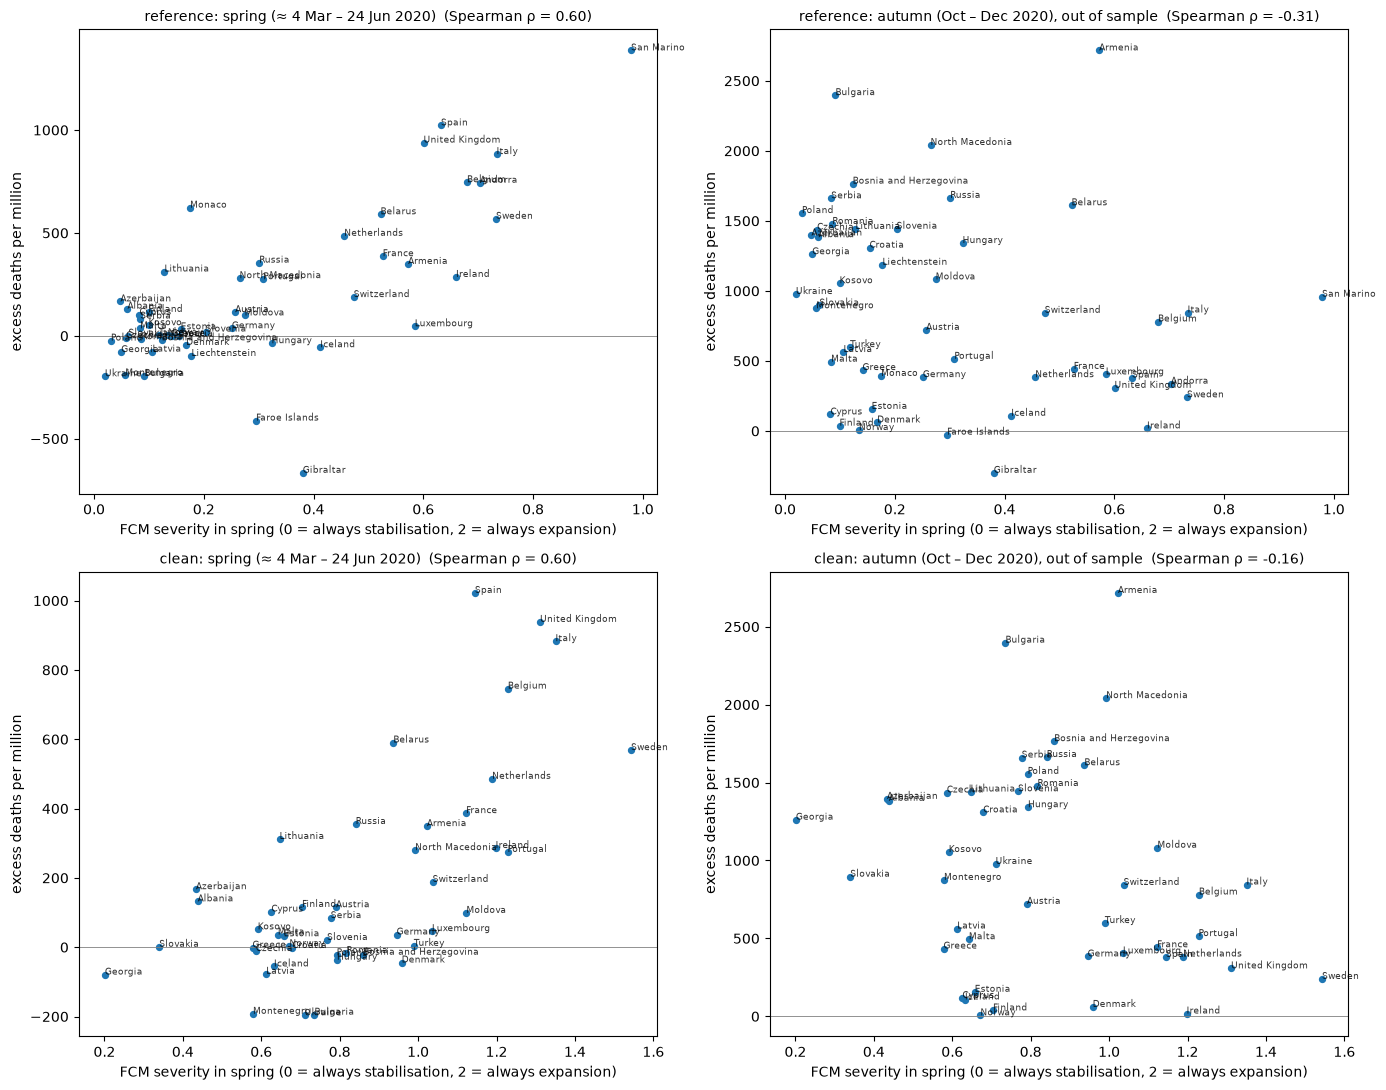

In [194]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for i, name in enumerate(["reference", "clean"]):
    V = val[name]
    for j, (col, title) in enumerate([("spring excess_per_million", "spring (≈ 4 Mar – 24 Jun 2020)"),
                                      ("autumn excess_per_million", "autumn (Oct – Dec 2020), out of sample")]):
        ax = axes[i, j]
        ok = V[[col, "severity"]].dropna()
        ax.scatter(ok["severity"], ok[col], s=18)
        for c_, r_ in ok.iterrows():
            ax.annotate(c_.replace("_", " "), (r_["severity"], r_[col]), fontsize=6.5, alpha=0.8)
        rho = corr.query("variant == @name and `FCM summary` == 'severity' and external == @col")["rho"].iloc[0]
        ax.axhline(0, color="grey", lw=0.6)
        ax.set_xlabel("FCM severity in spring (0 = always stabilisation, 2 = always expansion)")
        ax.set_ylabel("excess deaths per million")
        ax.set_title(f"{name}: {title}  (Spearman ρ = {rho:.2f})", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "covid_validation_severity_vs_excess.png", dpi=200)
plt.show()

### 11d: The "stable" countries: hidden excess deaths, testing, autumn

Countries with ≥ 90% of their days in stabilisation (reference) — what do the independent sources say?

In [195]:
V = val["reference"].copy()
V["excess / reported deaths"] = V["spring excess_per_million"] / V["reported deaths per million (spring)"].replace(0, np.nan)
stable = V[V["% stabilisation"] >= 90]
cols = ["% stabilisation", "entropy", "spring excess_per_million", "reported deaths per million (spring)",
        "excess / reported deaths", "tests per 1000 by 24 Jun", "mean positivity %", "autumn excess_per_million"]
print(f"{len(stable)} countries with >= 90% stabilisation days (reference)")
print("\nmedians, stable vs other countries:")
print(pd.DataFrame({"stable (>=90%)": stable[cols[2:]].median(),
                    "others": V[V["% stabilisation"] < 90][cols[2:]].median()}).round(1))
stable[cols].sort_values("spring excess_per_million", ascending=False).round(1)

23 countries with >= 90% stabilisation days (reference)

medians, stable vs other countries:
                                      stable (>=90%)  others
spring excess_per_million                        3.0   231.5
reported deaths per million (spring)            27.6   140.2
excess / reported deaths                         0.1     0.9
tests per 1000 by 24 Jun                        35.9    64.8
mean positivity %                                3.4     4.3
autumn excess_per_million                     1054.3   478.8


,% stabilisation,entropy,spring excess_per_million,reported deaths per million (spring),excess / reported deaths,tests per 1000 by 24 Jun,mean positivity %,autumn excess_per_million
countriesAndTerritories,,,,,,,,
Monaco,98.0,0.3,622.6,30.2,20.6,NaN,NaN,392.5
Russia,98.2,0.5,355.4,57.3,6.2,124.8,2.8,1663.7
Lithuania,92.4,0.2,312.2,27.6,11.3,139.5,1.1,1442.1
Azerbaijan,100.0,0.1,167.3,16.6,10.1,NaN,NaN,1395.4
Albania,98.1,0.1,132.1,15.7,8.4,7.5,10.5,1382.8
Finland,96.4,0.2,116.1,59.3,2.0,44.3,4.4,37.6
Cyprus,97.1,0.2,102.7,21.7,4.7,167.7,0.6,117.6
Serbia,100.0,0.2,83.9,37.8,2.2,52.2,10.7,1660.4
Kosovo,93.2,0.2,51.4,21.1,2.4,NaN,NaN,1054.3


## Step 12: What FCM adds over k-means (figure for the report)

k-means gives each country-day exactly one state; FCM gives a membership degree in every state. To show the
difference we run k-means (k = 3, 10 starts, seed 42) on the **same** z-scored reference matrix as FCM (Step 7),
order its clusters by mean x4 like the FCM states, and compare for three countries:
Poland (clear, low entropy), Germany (clear transitions), Italy (the most uncertain, highest entropy in the paper).

Rows of the figure: (1) k-means label as a coloured band, (2) FCM memberships, with the **transition days**
(largest membership < 0.6) shaded, (3) the daily entropy of the FCM classification (eq. 10).
Both variants are drawn (reference = the paper's data; clean = 7-day means, log1p).

In [196]:
from matplotlib.patches import Patch

KM_K = 3
km_labels = {}
for name in ["reference", "clean"]:
    km = KMeans(n_clusters=KM_K, n_init=N_INIT, random_state=SEED).fit(data[name])
    x4 = raw_frames[name]["x4"].to_numpy()
    order = np.argsort([x4[km.labels_ == j].mean() for j in range(KM_K)])
    rank = np.empty(KM_K, dtype=int); rank[order] = np.arange(KM_K)
    km_labels[name] = np.array(STATE_NAMES)[rank[km.labels_]]
    R = results7[name]
    agree = (km_labels[name] == R["state"].to_numpy()).mean() * 100
    trans = (R["max_u"] < 0.6).mean() * 100
    print(f"{name:10s} k-means vs FCM hard state: {agree:.1f}% identical | FCM transition days (max u < 0.6): {trans:.1f}%")
    print(pd.crosstab(pd.Series(km_labels[name], name="k-means"), R["state"].rename("FCM")).reindex(STATE_NAMES)[STATE_NAMES])

reference  k-means vs FCM hard state: 83.8% identical | FCM transition days (max u < 0.6): 18.1%
FCM              stabilisation  destabilisation  expansion
k-means                                                   
stabilisation             4626              911         20
destabilisation              0               47         17
expansion                    0               17        311
clean      k-means vs FCM hard state: 96.1% identical | FCM transition days (max u < 0.6): 27.9%
FCM              stabilisation  destabilisation  expansion
k-means                                                   
stabilisation             1341               11          0
destabilisation            100             2302          7
expansion                    0               70        955


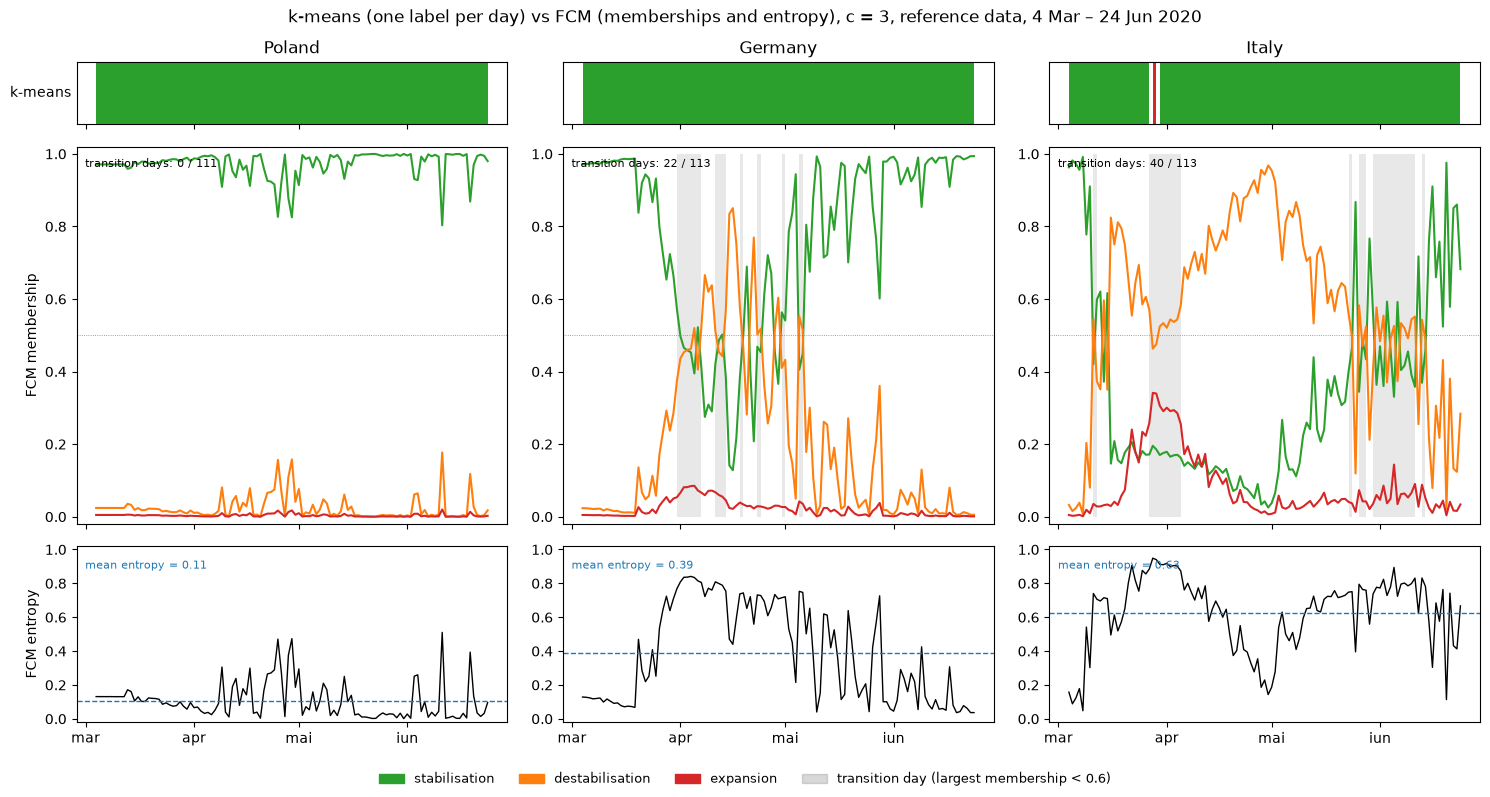

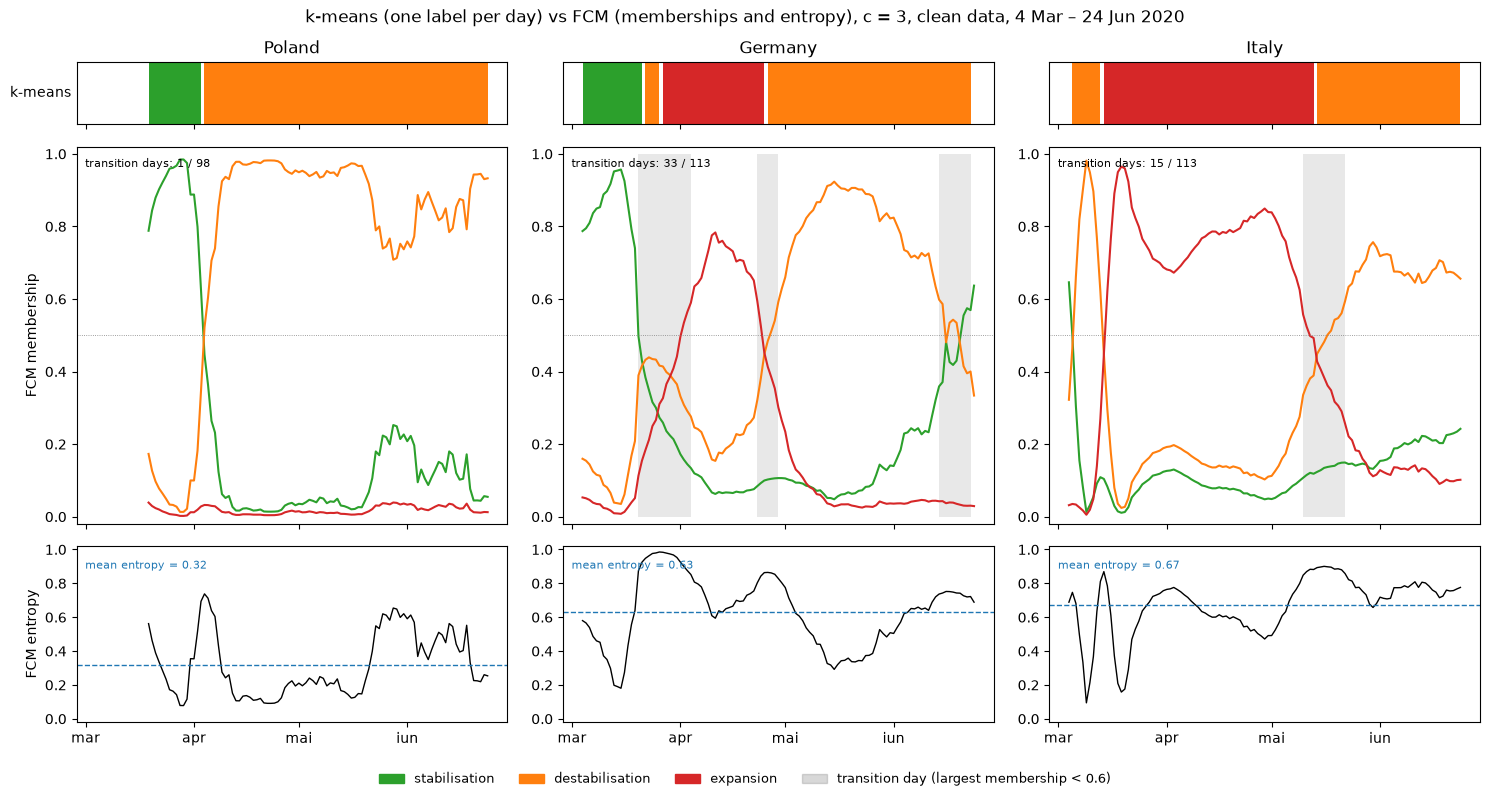

In [197]:
SHOW = ["Poland", "Germany", "Italy"]
TRANS_U = 0.6
for name in ["reference", "clean"]:
    R = results7[name].assign(km=km_labels[name])
    fig, axes = plt.subplots(3, len(SHOW), figsize=(15, 8), sharex=True,
                             gridspec_kw={"height_ratios": [0.5, 3, 1.4]})
    for j, country in enumerate(SHOW):
        Rc = R[R["countriesAndTerritories"] == country].sort_values("date")
        d_ = Rc["date"].to_numpy()
        # (1) k-means band
        ax = axes[0, j]
        for s in STATE_NAMES:
            ax.fill_between(d_, 0, 1, where=(Rc["km"] == s).to_numpy(), color=COLORS[s], step="mid", lw=0)
        ax.set_yticks([]); ax.set_ylim(0, 1)
        ax.set_title(country, fontsize=12)
        if j == 0:
            ax.set_ylabel("k-means", rotation=0, ha="right", va="center")
        # (2) FCM memberships + transition days
        ax = axes[1, j]
        tr = (Rc["max_u"] < TRANS_U).to_numpy()
        ax.fill_between(d_, 0, 1, where=tr, color="grey", alpha=0.18, step="mid", lw=0)
        for s in STATE_NAMES:
            ax.plot(d_, Rc[f"u_{s}"], color=COLORS[s], lw=1.5)
        ax.axhline(0.5, color="grey", lw=0.6, ls=":")
        ax.set_ylim(-0.02, 1.02)
        ax.text(0.02, 0.97, f"transition days: {tr.sum()} / {len(tr)}", transform=ax.transAxes, fontsize=8, va="top")
        if j == 0:
            ax.set_ylabel("FCM membership")
        # (3) daily entropy + country mean
        ax = axes[2, j]
        ax.plot(d_, Rc["H_day"], color="black", lw=1)
        ax.axhline(Rc["H_day"].mean(), color="tab:blue", lw=1, ls="--")
        ax.text(0.02, 0.92, f"mean entropy = {Rc['H_day'].mean():.2f}", transform=ax.transAxes, fontsize=8, va="top",
                color="tab:blue")
        ax.set_ylim(-0.02, 1.02)
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        if j == 0:
            ax.set_ylabel("FCM entropy")
    handles = [Patch(color=COLORS[s], label=s) for s in STATE_NAMES] + \
              [Patch(color="grey", alpha=0.3, label=f"transition day (largest membership < {TRANS_U})")]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, frameon=False)
    fig.suptitle(f"k-means (one label per day) vs FCM (memberships and entropy), c = 3, {name} data, 4 Mar – 24 Jun 2020",
                 fontsize=12)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(FIG_DIR / f"covid_kmeans_vs_fcm_{name}.png", dpi=200)
    plt.show()

## Step 13: FCM without the paper's 4 derived variables (raw counts)

Same idea as the unscaled test on WDBC: what happens if we skip the feature engineering? The paper's x1–x3 are
derived by us from the file (divided by population, deaths/cases ratio). Here we keep **the same country-days**
as the reference variant (55 ECDC Europe countries, 4 Mar – 24 Jun 2020, negatives set to 0) and the same
z-score + FCM settings (c = 3, m = 2, 10 starts, seed 42), but use only columns that are in the file as they are:

- **raw A**: daily `cases`, daily `deaths` (absolute numbers per day);
- **raw B**: daily `cases`, daily `deaths`, plus the file's 14-day rate per 100,000 (= the paper's x4, which ECDC
  computes, not us).

Hypothesis (**not tested yet**): without dividing by population, FCM groups countries by size, not by their
epidemic situation (large countries "in expansion", small countries with high rates "stable").

There are no true labels, so "performance" is measured three ways:
1. agreement with the reference partition (Step 7): ARI, and % of country-days with the same hard state;
2. external validation (Step 11): Spearman ρ between a country's mean severity and its spring excess mortality
   (reference: ρ ≈ 0.60);
3. Spearman ρ between a country's mean severity and its population: high |ρ| = the clusters follow country size.

Severity = u(destabilisation) + 2·u(expansion), states ordered by the membership-weighted mean of x4 as in Step 7.

In [198]:
from itertools import permutations
from sklearn.metrics import adjusted_rand_score

# same rows, same order as `ref` (Step 4): in_window, 55 countries, sorted by country and date
raw = in_window[in_window["countriesAndTerritories"].isin(COUNTRY_SETS["55"])].copy()
raw = raw.sort_values(["countriesAndTerritories", "date"]).reset_index(drop=True)
raw["cases"] = raw["cases"].clip(lower=0)
raw["deaths"] = raw["deaths"].clip(lower=0)
raw["rate14"] = raw[RATE14].fillna(0.0)
assert (raw[["countriesAndTerritories", "date"]].to_numpy() == ref[["countriesAndTerritories", "date"]].to_numpy()).all()

RAW_VARIANTS = {"raw A: cases, deaths": ["cases", "deaths"],
                "raw B: cases, deaths, 14-day rate": ["cases", "deaths", "rate14"]}
print(raw[["cases", "deaths", "rate14"]].describe().round(2))
print("\nSpearman correlation with population (country-days):")
print(raw[["cases", "deaths", "rate14"]].rank().corrwith(raw["popData2019"].rank()).round(2))   # Pearson on ranks = Spearman

          cases   deaths   rate14
count   5949.00  5949.00  5949.00
mean     419.76    32.43    39.66
std     1239.66   118.99    74.35
min        0.00     0.00     0.00
25%        3.00     0.00     3.85
50%       30.00     1.00    13.03
75%      237.00     8.00    40.90
max    11656.00  2004.00   858.90

Spearman correlation with population (country-days):
cases     0.79
deaths    0.70
rate14    0.10
dtype: float64


In [199]:
def fcm_states(cols):
    """FCM c = 3 on the z-scored columns; returns a frame like results7[...] (u_*, state, max_u, H_day)."""
    Z = raw[cols].to_numpy(dtype=float)
    Z = (Z - Z.mean(axis=0)) / Z.std(axis=0)
    best, info = fcm.fcm_multistart(Z, C_PAPER, m=M_MAIN, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
    U = best.U.T
    x4 = ref["x4"].to_numpy()
    U = U[:, np.argsort((U * x4[:, None]).sum(axis=0) / U.sum(axis=0))]
    R = ref[["countriesAndTerritories", "date", "popData2019"]].join(raw[cols])
    for j, s in enumerate(STATE_NAMES):
        R[f"u_{s}"] = U[:, j]
    R["state"] = np.array(STATE_NAMES)[U.argmax(axis=1)]
    R["max_u"] = U.max(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        R["H_day"] = -np.nansum(np.where(U > 0, U * np.log(U) / np.log(C_PAPER), 0.0), axis=1)
    return R, fcm.validity_indices(Z, best, M_MAIN), info

def best_perm_agreement(a, b):
    """% same label after the best relabelling of b (independent of how the states are ordered)."""
    return max((a == pd.Series(b).map(dict(zip(STATE_NAMES, p))).to_numpy()).mean() * 100
               for p in permutations(STATE_NAMES))

ref_best = grid_runs[("reference", C_PAPER)]   # the Step 7 run
runs13 = {"reference (x1-x4)": (results7["reference"], fcm.validity_indices(data["reference"], ref_best, M_MAIN), None)}
for name, cols in RAW_VARIANTS.items():
    runs13[name] = fcm_states(cols)

pop = ref.groupby("countriesAndTerritories")["popData2019"].first()
ref_state = results7["reference"]["state"].to_numpy()
rows13, summ13 = [], {}
for name, (R, idx, info) in runs13.items():
    S = country_summary(R).join(ext, how="left").join(pop.rename("population"))
    summ13[name] = S
    rho_ex, p_ex, n_ex = perm_spearman(S["severity"], S["spring excess_per_million"])
    rho_pop, p_pop, n_pop = perm_spearman(S["severity"], S["population"])
    rows13.append({
        "variant": name,
        "NPC": idx["NPC"] if idx else np.nan,
        "starts at best J": info["n_at_best"] if info else np.nan,
        "ARI vs reference": adjusted_rand_score(ref_state, R["state"]),
        "same state % (x4 order)": (R["state"].to_numpy() == ref_state).mean() * 100,
        "same state % (best relabelling)": best_perm_agreement(ref_state, R["state"].to_numpy()),
        **{f"% {s}": (R["state"] == s).mean() * 100 for s in STATE_NAMES},
        "rho severity vs spring excess": rho_ex, "p (excess)": p_ex, "n (excess)": n_ex,
        "rho severity vs population": rho_pop, "p (population)": p_pop, "n (population)": n_pop,
    })
raw_test = pd.DataFrame(rows13).set_index("variant")
raw_test.to_csv(OUT_DIR / "covid_raw_features_test.csv")
print("saved: covid_raw_features_test.csv")
raw_test.T.round(2).astype(str)   # astype(str) only for display (no scientific notation)

saved: covid_raw_features_test.csv


variant,reference (x1-x4),"raw A: cases, deaths","raw B: cases, deaths, 14-day rate"
NPC,0.68,0.94,0.84
starts at best J,NaN,10.0,10.0
ARI vs reference,1.0,0.13,0.49
same state % (x4 order),100.0,76.9,83.93
same state % (best relabelling),100.0,78.45,83.93
% stabilisation,77.76,95.23,86.91
% destabilisation,16.39,2.12,4.67
% expansion,5.85,2.66,8.42
rho severity vs spring excess,0.6,0.43,0.57
p (excess),0.0,0.0,0.0


### 13a: Which countries end up "in expansion"?

The 10 countries with the highest mean severity in each variant, with their population. If the hypothesis holds,
the raw variants should list the large countries (Russia, UK, Germany, Italy, Spain, France…), while the reference
lists countries with high rates relative to population.

In [200]:
top13 = pd.concat({name: S.sort_values("severity", ascending=False).head(10)[["severity", "population"]]
                         .reset_index().rename(columns={"countriesAndTerritories": "country"})
                   for name, S in summ13.items()}, axis=1)
top13[[c for c in top13.columns if c[1] == "population"]] = top13[[c for c in top13.columns if c[1] == "population"]] / 1e6
print("population in millions")
top13.round(2)

population in millions


reference (x1-x4)                     raw A: cases, deaths           \
            country severity population              country severity   
0        San_Marino     0.98       0.03       United_Kingdom     0.88   
1             Italy     0.73      60.36                Italy     0.83   
2            Sweden     0.73      10.23                Spain     0.68   
3           Andorra     0.70       0.08               Russia     0.65   
4           Belgium     0.68      11.46               France     0.57   
5           Ireland     0.66       4.90              Germany     0.32   
6             Spain     0.63      46.94               Turkey     0.29   
7          Holy_See     0.61       0.00              Belgium     0.15   
8    United_Kingdom     0.60      66.65          Netherlands     0.06   
9        Luxembourg     0.58       0.61               Sweden     0.04   

             raw B: cases, deaths, 14-day rate                      
  population                           country severity population  
0      66.65                        San_Marino     1.16       0.03  
1      60.36                          Holy_See     0.77       0.00  
2      46.94                           Belarus     0.71       9.45  
3     145.87                           Andorra     0.68       0.08  
4      67.01                    United_Kingdom     0.66      66.65  
5      83.02                            Russia     0.65     145.87  
6      82.00                           Armenia     0.61       2.96  
7      11.46                             Italy     0.60      60.36  
8      17.28                             Spain     0.54      46.94  
9      10.23                        Luxembourg     0.53       0.61

In [201]:
H13 = pd.DataFrame({name: S["severity"] for name, S in summ13.items()}).reindex(FIG2_COUNTRIES)
print("mean severity of the paper's 8 countries (0 = always stabilisation, 2 = always expansion):")
H13.round(2)

mean severity of the paper's 8 countries (0 = always stabilisation, 2 = always expansion):


,reference (x1-x4),"raw A: cases, deaths","raw B: cases, deaths, 14-day rate"
countriesAndTerritories,,,
Poland,0.03,0.00,0.01
Czechia,0.06,0.00,0.01
Slovakia,0.06,0.00,0.01
Germany,0.25,0.32,0.39
France,0.53,0.57,0.47
Italy,0.73,0.83,0.60
Greece,0.14,0.00,0.01
Spain,0.63,0.68,0.54


## Step 14: Figures for the report (same types as for WDBC)

Made from variables already computed above (no new clustering). Saved to `figures/covid/` with the prefix `covid_report_`, 300 dpi.
**reference** = the paper's preprocessing (z-score); **clean** = our variant (log1p + z-score).

reference, Pearson:
      x1    x2    x3    x4
x1  1.00  0.17 -0.02  0.45
x2  0.17  1.00  0.33  0.39
x3 -0.02  0.33  1.00  0.04
x4  0.45  0.39  0.04  1.00

clean, Pearson:
      x1    x2    x3    x4
x1  1.00  0.63  0.10  0.94
x2  0.63  1.00  0.49  0.61
x3  0.10  0.49  1.00  0.23
x4  0.94  0.61  0.23  1.00



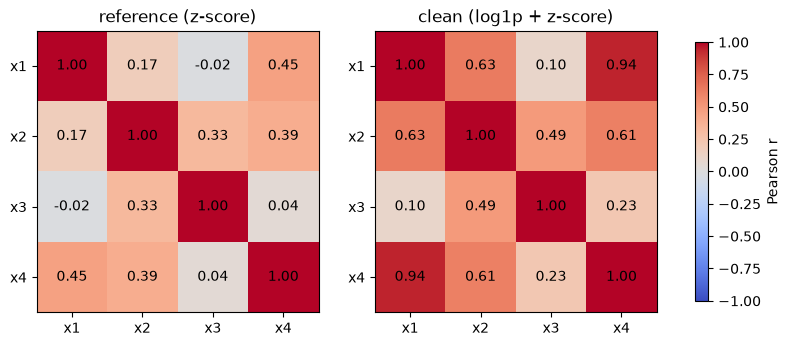

In [202]:
# Pearson correlation of x1-x4 (FCM input of each variant)
VARIANT_LABELS = {"reference": "reference (z-score)", "clean": "clean (log1p + z-score)"}
FCM_INPUT = {"reference": ref_z, "clean": clean_z}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, Zf) in zip(axes, FCM_INPUT.items()):
    C = Zf[FEATS].corr(method="pearson")
    im = ax.imshow(C, vmin=-1, vmax=1, cmap="coolwarm")
    for i in range(len(FEATS)):
        for j in range(len(FEATS)):
            ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_xticks(range(len(FEATS)), FEATS)
    ax.set_yticks(range(len(FEATS)), FEATS)
    ax.set_title(VARIANT_LABELS[name])
    print(f"{name}, Pearson:\n{C.round(2)}\n")
fig.colorbar(im, ax=axes, shrink=0.8, label="Pearson r")
fig.savefig(FIG_DIR / "covid_report_correlation_pearson.png", dpi=300, bbox_inches="tight")
plt.show()

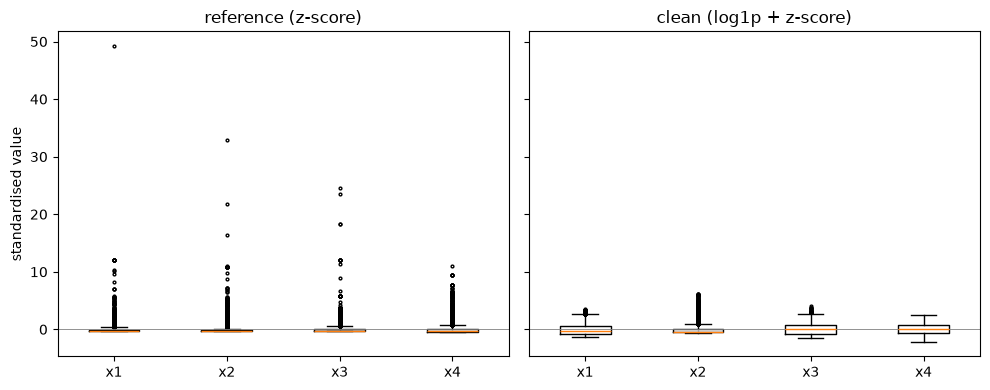

skewness:
     reference  clean
x1      24.00   0.95
x2      12.29   2.87
x3      10.45   0.27
x4       4.14  -0.00

largest standardised value:
     reference  clean
x1       49.2    3.5
x2       32.9    6.1
x3       24.5    4.1
x4       11.0    2.5


In [203]:
# Distributions of x1-x4 after each preprocessing (as the WDBC boxplots)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, Zf) in zip(axes, FCM_INPUT.items()):
    ax.boxplot([Zf[f] for f in FEATS], whis=1.5, flierprops={"markersize": 2})
    ax.set_xticks(range(1, len(FEATS) + 1), FEATS)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(VARIANT_LABELS[name])
axes[0].set_ylabel("standardised value")
fig.tight_layout()
fig.savefig(FIG_DIR / "covid_report_scaling_comparison.png", dpi=300)
plt.show()
print("skewness:\n", pd.DataFrame({n: Zf[FEATS].skew() for n, Zf in FCM_INPUT.items()}).round(2))
print("\nlargest standardised value:\n", pd.DataFrame({n: Zf[FEATS].max() for n, Zf in FCM_INPUT.items()}).round(1))

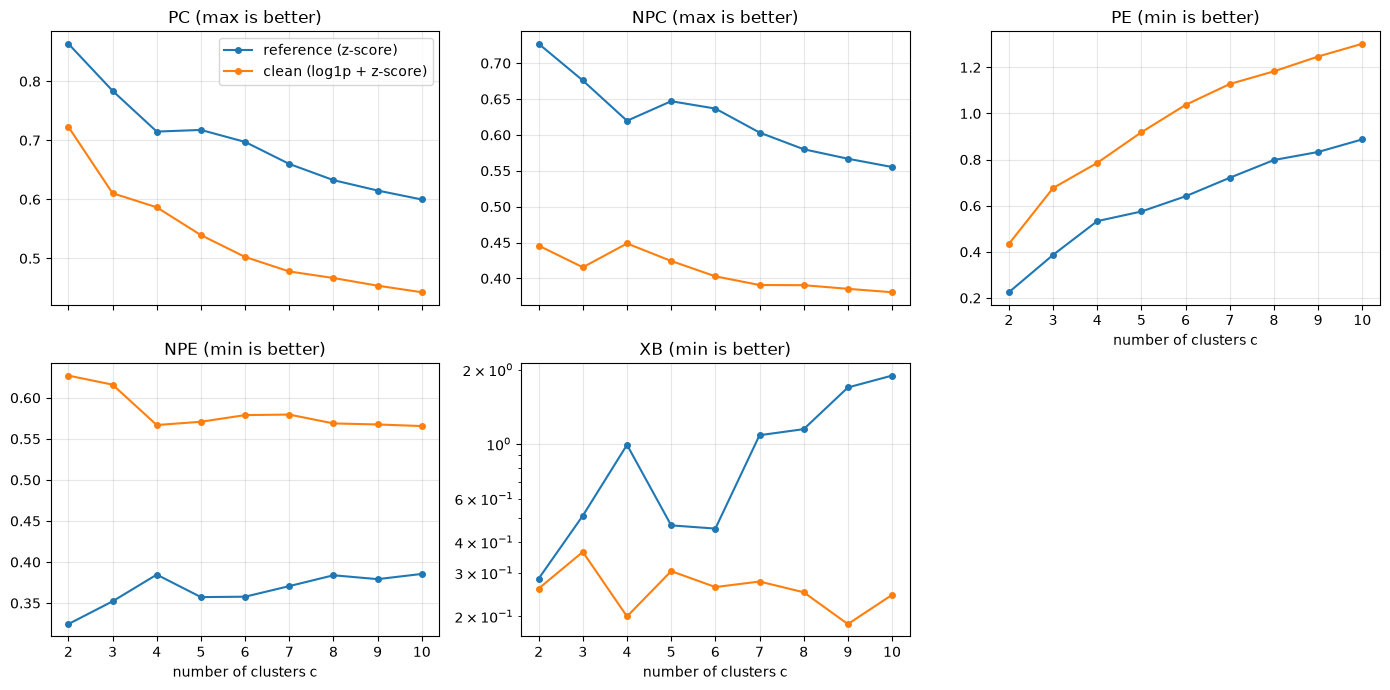

           PC  NPC  PE  NPE  XB  FS  KL (k-means, first local max)
variant                                                           
reference   2    2   2    2   2  10                              2
clean       2    4   2   10   9  10                              2


In [204]:
# Validity indices vs c (m = 2, best of 10 starts), from Step 6b
g6 = grid[grid["variant"].isin(["reference", "clean"])]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
PLOT_INDICES = {k: v for k, v in INDICES.items() if k != "FS"}   # FS is not used in the report
for ax, (idx, best_dir) in zip(axes.ravel(), PLOT_INDICES.items()):
    for name, g in g6.groupby("variant", sort=False):
        ax.plot(g["c"], g[idx], marker="o", markersize=4, label=VARIANT_LABELS[name])
    if idx == "XB":
        ax.set_yscale("log")
    ax.set_title(f"{idx} ({best_dir} is better)")
    ax.set_xticks(list(C_RANGE))
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("number of clusters c")
axes[1, 2].axis("off")                    # 5 indices in a 2 x 3 grid
axes[0, 2].tick_params(labelbottom=True)
axes[0, 2].set_xlabel("number of clusters c")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "covid_report_validity_indices.png", dpi=300)
plt.show()
print(pref.loc[["reference", "clean"]])

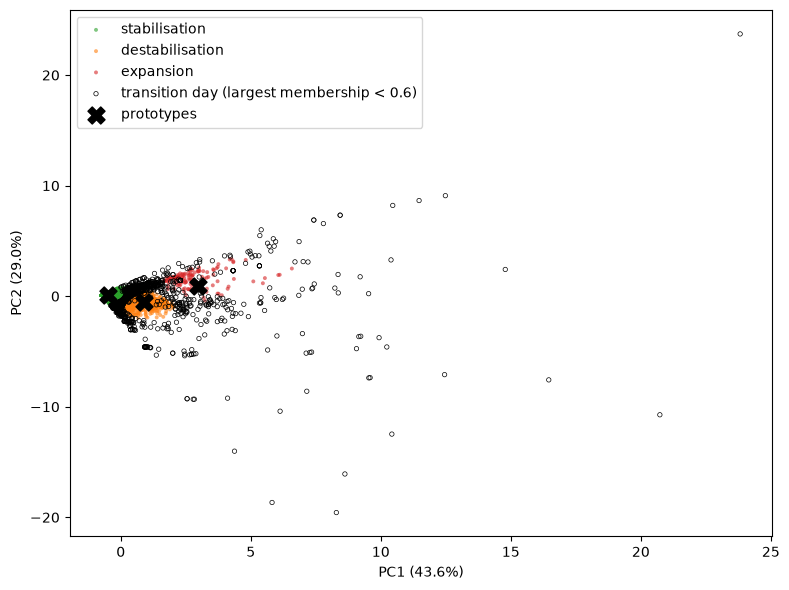

explained variance PC1 + PC2: 72.5%
transition days: 1077 of 5949
prototypes (z-units):
                    x1    x2    x3    x4
stabilisation   -0.19 -0.23 -0.22 -0.34
destabilisation  0.20  0.62  0.68  0.42
expansion        1.44  0.96  0.20  2.74


In [205]:
# Reference, FCM c = 3, m = 2, country-days projected on PC1-PC2
TRANS_U = 0.6                                   # transition day: largest membership < 0.6 (Step 12)
A = data["reference"]
R = results7["reference"]
run = grid_runs[("reference", C_PAPER)]
x4 = ref["x4"].to_numpy()
order = np.argsort((run.U.T * x4[:, None]).sum(axis=0) / run.U.T.sum(axis=0))   # same ordering as Step 7
V = run.V[order]

mu = A.mean(axis=0)
_, s_vals, Vt = np.linalg.svd(A - mu, full_matrices=False)
P = (A - mu) @ Vt[:2].T
proto_P = (V - mu) @ Vt[:2].T
expl = s_vals ** 2 / (s_vals ** 2).sum()
trans = R["max_u"].to_numpy() < TRANS_U

fig, ax = plt.subplots(figsize=(8, 6))
for s in STATE_NAMES:
    sel = (R["state"].to_numpy() == s) & ~trans
    ax.scatter(P[sel, 0], P[sel, 1], s=8, color=COLORS[s], alpha=0.6, edgecolors="none", label=s)
ax.scatter(P[trans, 0], P[trans, 1], s=10, facecolors="none", edgecolors="black", linewidths=0.5,
           label=f"transition day (largest membership < {TRANS_U})")
ax.scatter(proto_P[:, 0], proto_P[:, 1], c="black", marker="X", s=150, label="prototypes")
ax.set_xlabel(f"PC1 ({expl[0]:.1%})")
ax.set_ylabel(f"PC2 ({expl[1]:.1%})")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "covid_report_fcm_pca_projection.png", dpi=300)
plt.show()
print("explained variance PC1 + PC2:", f"{expl[:2].sum():.1%}")
print("transition days:", int(trans.sum()), "of", len(trans))
print("prototypes (z-units):\n", pd.DataFrame(V, index=STATE_NAMES, columns=FEATS).round(2))

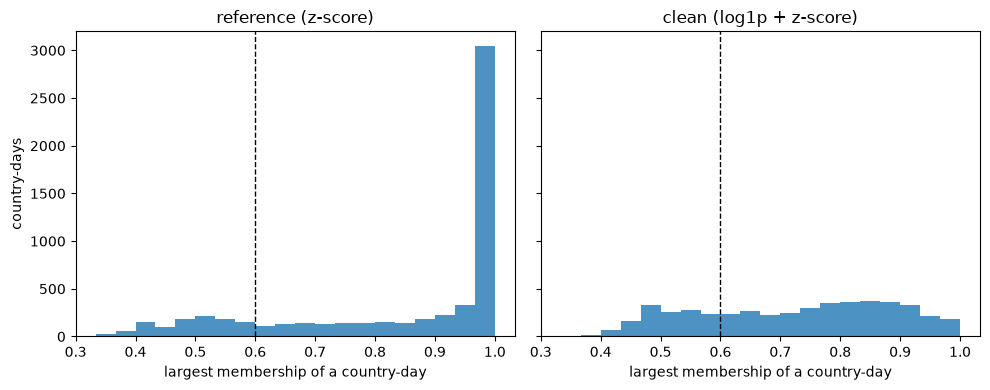

,country-days,max u < 0.5 %,max u < 0.6 %,max u >= 0.9 %,median max u
variant,,,,,
reference,5949,8.76,18.10,60.51,0.97
clean,4786,12.06,27.94,15.27,0.74


In [206]:
# Largest membership per country-day, reference vs clean
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
bins = np.linspace(1 / C_PAPER, 1, 21)          # with c = 3 the largest membership is at least 1/3
rows = []
for ax, name in zip(axes, ["reference", "clean"]):
    u = results7[name]["max_u"]
    ax.hist(u, bins=bins, alpha=0.8)
    ax.axvline(TRANS_U, color="black", ls="--", lw=1)
    ax.set_title(VARIANT_LABELS[name])
    ax.set_xlabel("largest membership of a country-day")
    rows.append({"variant": name, "country-days": len(u), "max u < 0.5 %": (u < 0.5).mean() * 100,
                 f"max u < {TRANS_U} %": (u < TRANS_U).mean() * 100, "max u >= 0.9 %": (u >= 0.9).mean() * 100,
                 "median max u": u.median()})
axes[0].set_ylabel("country-days")
fig.tight_layout()
fig.savefig(FIG_DIR / "covid_report_max_membership_hist.png", dpi=300)
plt.show()
pd.DataFrame(rows).set_index("variant").round(2)